# DICE FEST 2026 — Machine Learning: The Urban Energy Transition Trilemma

In [1]:
# Reproducibility flags harus di-set SEBELUM torch/BLAS diinisialisasi
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"
os.environ["PYTHONHASHSEED"] = "42"
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
_ = os.environ.setdefault("MKL_NUM_THREADS", "4")

## 1. Setup & Konfigurasi

In [2]:
import sys, gc, time, glob, random, hashlib, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from sklearn.model_selection import KFold
import lightgbm as lgb
import torch

from scipy.optimize import nnls
from scipy.special import ndtri

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)

SEED = 42
N_FOLDS = 5
# Jumlah thread DIKUNCI (bukan os.cpu_count()). Dengan seed tetap + LightGBM deterministic + force_col_wise, re-run memberi
# output bit-identik pada stack referensi yang sama (OS, CPU/ISA, GPU, versi library — lihat cetakan environment di bawah).
# Pada hardware lain hasil tetap deterministik, namun digit terakhir dapat berbeda (kernel BLAS/cuBLAS berbeda).
N_THREADS = 12
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"   # MLP multi-task (GPU deterministik; fallback CPU)
if DEVICE != "cuda":
    print("!! PERINGATAN: CUDA tidak tersedia -> MLP multi-task dilatih di CPU (stream RNG berbeda); "
          "prediksi tidak akan bit-identik dengan submisi referensi yang dibuat di GPU.")
# Cache prediksi per-model di artifacts/: bila file cache dari run sebelumnya (kode yang sama) ada, dipakai ulang; bila tidak ada,
# model dilatih. Set environment DICE_RECOMPUTE=1 untuk memaksa semua model dilatih ulang dari nol.
RECOMPUTE = os.environ.get("DICE_RECOMPUTE", "0") == "1"
ART_DIR = Path("artifacts"); ART_DIR.mkdir(exist_ok=True)

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False; torch.backends.cudnn.deterministic = True
seed_everything()

def cached(name, fn):
    """Jalankan fn() dan simpan hasil (dict of np.ndarray) ke ART_DIR/name.npz; pakai cache bila RECOMPUTE=False."""
    path = ART_DIR / f"{name}.npz"
    if not RECOMPUTE and path.exists():
        z = np.load(path); print(f"[cache] {name} dimuat dari {path}"); return {k: z[k] for k in z.files}
    t0 = time.time(); out = fn()
    np.savez(path, **out); print(f"[{name}] selesai dalam {(time.time() - t0) / 60:.1f} menit")
    return out

def find_data_dir():
    cands = [Path("datasets"), Path("."), Path("../datasets"), Path("data")]
    cands += [Path(p).parent for p in glob.glob("/kaggle/input/**/train.csv", recursive=True)]
    for p in cands:
        if (p / "train.csv").exists() and (p / "test.csv").exists():
            return p
    raise FileNotFoundError("train.csv / test.csv tidak ditemukan")

DATA_DIR = find_data_dir()
OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
print("DATA_DIR:", DATA_DIR.resolve(), "| OUT_DIR:", OUT_DIR.resolve())
print("python", platform.python_version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| lightgbm", lgb.__version__, "| torch", torch.__version__, "| scipy", __import__("scipy").__version__,
      "| sklearn", __import__("sklearn").__version__)
print("platform:", platform.platform(), "|", platform.processor(), "| torch CUDA", torch.version.cuda,
      "| cuDNN", torch.backends.cudnn.version() if torch.cuda.is_available() else None)
print("CPU threads:", N_THREADS, "| CUDA:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

# palet chart (colorblind-safe, urutan kategori tetap)
C1, C2, C3 = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
DIVERGING = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])
mpl.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titlecolor": INK,
                     "font.size": 9, "figure.dpi": 110})

DATA_DIR: D:\ITS\S1\Lomba\FORTEX\penyisihan1\datasets | OUT_DIR: D:\ITS\S1\Lomba\FORTEX\penyisihan1
python 3.12.10 | numpy 2.4.6 | pandas 2.3.3 | lightgbm 4.6.0 | torch 2.11.0+cu128 | scipy 1.17.1 | sklearn 1.6.1
platform: Windows-11-10.0.26200-SP0 | Intel64 Family 6 Model 198 Stepping 2, GenuineIntel | torch CUDA 12.8 | cuDNN 91900
CPU threads: 12 | CUDA: True NVIDIA GeForce RTX 5070 Ti Laptop GPU


## 2. Memuat Data

In [3]:
TARGETS = ["target_macro_gas_kwh", "target_macro_elec_kwh", "target_eui_gas_kwh_per_sqm",
           "target_clean_building_ratio", "target_electric_heating_adoption"]
SIGMA = {"target_macro_gas_kwh": 151750.04, "target_macro_elec_kwh": 41725.37, "target_eui_gas_kwh_per_sqm": 40.65,
         "target_clean_building_ratio": 12.49, "target_electric_heating_adoption": 7.18}
G, E, U, CL, EH = TARGETS
HVAC = [f"hvac_dist_{i:02d}" for i in range(1, 11)]

def nrmse(y, p, t):
    return float(np.sqrt(np.mean((np.asarray(y, dtype=np.float64) - np.asarray(p, dtype=np.float64)) ** 2)) / SIGMA[t])

def column_wise_nrmse(y_true: pd.DataFrame, y_pred: pd.DataFrame):
    """Metrik resmi: rata-rata RMSE_k / sigma_k atas 5 target."""
    per = {t: nrmse(y_true[t], y_pred[t], t) for t in TARGETS}
    return float(np.mean(list(per.values()))), per

t0 = time.time()
train_raw = pd.read_csv(DATA_DIR / "train.csv")
test_raw = pd.read_csv(DATA_DIR / "test.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")
print(f"train {train_raw.shape} | test {test_raw.shape} | sample_submission {sample_sub.shape} | {time.time()-t0:.1f}s")

# Mode uji cepat pipeline (subsampel + round kecil). Submisi resmi dibuat dengan FAST_DEV_RUN = False.
FAST_DEV_RUN = os.environ.get("DICE_FAST_DEV_RUN") == "1"
if FAST_DEV_RUN:
    train_raw = train_raw.sample(40000, random_state=SEED).reset_index(drop=True)
    test_raw = test_raw.iloc[:20000].reset_index(drop=True); sample_sub = sample_sub.iloc[:20000].reset_index(drop=True)
    ART_DIR = Path("artifacts_dev"); ART_DIR.mkdir(exist_ok=True)
    print("FAST_DEV_RUN aktif:", train_raw.shape, test_raw.shape)
def R(n):
    """Jumlah round/epoch: penuh untuk run resmi, diperkecil hanya pada FAST_DEV_RUN."""
    return max(2, n // 100) if FAST_DEV_RUN else n
train_raw.head(3)

train (429303, 209) | test (183987, 204) | sample_submission (183987, 6) | 14.0s


,id,socio_demog_001,bld_dim_01,bld_dim_02,socio_demog_002,bld_dim_03,bld_dim_04,bld_dim_05,bld_dim_06,bld_dim_07,bld_dim_08,bld_dim_09,bld_dim_10,bld_dim_11,bld_dim_12,bld_dim_13,socio_demog_003,bld_dim_14,bld_dim_15,bld_dim_16,socio_demog_004,bld_era_01,bld_dim_17,bld_dim_18,bld_era_02,...,socio_demog_116,socio_demog_117,socio_demog_118,socio_demog_119,socio_demog_120,socio_demog_121,socio_demog_122,socio_demog_123,socio_demog_124,socio_demog_125,socio_demog_126,env_climate_01,env_climate_02,env_climate_03,env_climate_04,env_climate_05,env_climate_06,socio_demog_127,zone_region_id,subzone_id,target_macro_gas_kwh,target_macro_elec_kwh,target_eui_gas_kwh_per_sqm,target_clean_building_ratio,target_electric_heating_adoption
0,ID_000001,100.0,23.0,23.0,1480.7,2863.1,2965.12,2961.40,1659.647850,1718.946106,1716.795904,0.0,0.0,0.0,23.0,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,3.482062,Medium (0-6%),0.0,...,0.000000,0.0,0.0,0.000000,0.000000,0.00000,34.294872,1.602564,1.602564,2.884615,1.602564,47.104263,4.457472,7.261773,4.457472,39.842490,0.0,0.0,REG_135,SUB_107385,233784.648889,63754.662,140.864009,100.00,2.797203
1,ID_000002,100.0,54.0,29.0,2707.3,5414.6,4672.71,5400.92,3126.328552,2718.896143,3117.913537,0.0,0.0,0.0,28.0,25.0,533.200001,533.200001,533.200001,533.200001,0.0,0.0,14.370073,Low (6-18%),0.0,...,0.250627,0.0,0.0,0.000000,0.000000,0.75188,17.042607,3.508772,4.761905,4.761905,2.005013,45.445663,3.832761,6.549348,3.832761,38.896315,0.0,25.0,REG_113,SUB_99382,266577.275347,90421.126,85.268477,53.70,6.289308
2,ID_000003,100.0,65.0,32.0,2194.8,4389.6,4394.24,4389.60,2908.406343,2911.479902,2908.406343,0.0,0.0,0.0,32.0,33.0,722.899997,878.099996,803.003222,722.899997,0.0,0.0,0.105667,High (<0%),0.0,...,0.480769,0.0,0.0,0.480769,0.240385,0.00000,16.105769,5.288462,4.567308,2.884615,1.201923,50.581011,4.858140,6.861478,4.858140,43.719532,0.0,30.0,REG_290,SUB_09223,568678.875801,98792.374,195.529375,49.23,4.687500


## 3. Exploratory Data Analysis
### 3.1 Struktur kolom & nilai hilang

In [4]:
groups = {"bld_dim": "bld_dim_", "bld_era": "bld_era_", "hvac_dist": "hvac_dist_", "env_climate": "env_climate_", "socio_demog": "socio_demog_"}
feat_cols_raw = [c for c in test_raw.columns if c not in ["id", "zone_region_id", "subzone_id"]]
print("Jumlah fitur per prefix:", {k: sum(c.startswith(v) for c in feat_cols_raw) for k, v in groups.items()})
print("Kolom non-numerik:", train_raw.select_dtypes("object").columns.tolist())
for c in ["bld_dim_18", "socio_demog_016"]:
    print(f"  {c}:", train_raw[c].value_counts().to_dict())
na_tr, na_te = train_raw.isna().sum(), test_raw.isna().sum()
print("Kolom dengan missing (train):", na_tr[na_tr > 0].to_dict(), "| (test):", na_te[na_te > 0].to_dict())
const_cols = [c for c in feat_cols_raw if train_raw[c].nunique(dropna=False) <= 1]
print(f"Fitur konstan ({len(const_cols)}):", const_cols)
print("Target missing:", train_raw[TARGETS].isna().sum().sum())

Jumlah fitur per prefix: {'bld_dim': 43, 'bld_era': 15, 'hvac_dist': 10, 'env_climate': 6, 'socio_demog': 127}
Kolom non-numerik: ['id', 'bld_dim_18', 'socio_demog_016', 'zone_region_id', 'subzone_id']
  bld_dim_18: {'High (<0%)': 218192, 'Medium (0-6%)': 103416, 'Low (6-18%)': 64634, 'Very Low (>18%)': 43061}
  socio_demog_016: {'Urban': 376496, 'Rural': 52807}
Kolom dengan missing (train): {'bld_dim_04': 695, 'bld_dim_07': 695} | (test): {'bld_dim_04': 336, 'bld_dim_07': 336}
Fitur konstan (11): ['socio_demog_001', 'socio_demog_004', 'bld_era_01', 'socio_demog_026', 'socio_demog_034', 'socio_demog_039', 'socio_demog_045', 'socio_demog_054', 'socio_demog_060', 'socio_demog_069', 'env_climate_06']
Target missing: 0


### 3.2 Distribusi target

,count,mean,std,min,1%,50%,99%,max,frozen_sigma
target_macro_gas_kwh,429303.0,230372.428,151750.038,4324.152,35396.070,193549.477,712162.136,999764.899,151750.04
target_macro_elec_kwh,429303.0,63755.899,41725.369,2967.900,10029.009,53838.933,194169.914,396491.975,41725.37
target_eui_gas_kwh_per_sqm,429303.0,139.063,40.652,5.121,61.939,134.848,264.998,648.107,40.65
target_clean_building_ratio,429303.0,90.763,12.491,8.330,50.000,96.300,100.000,100.000,12.49
target_electric_heating_adoption,429303.0,5.380,7.185,0.000,0.000,3.101,36.879,93.237,7.18


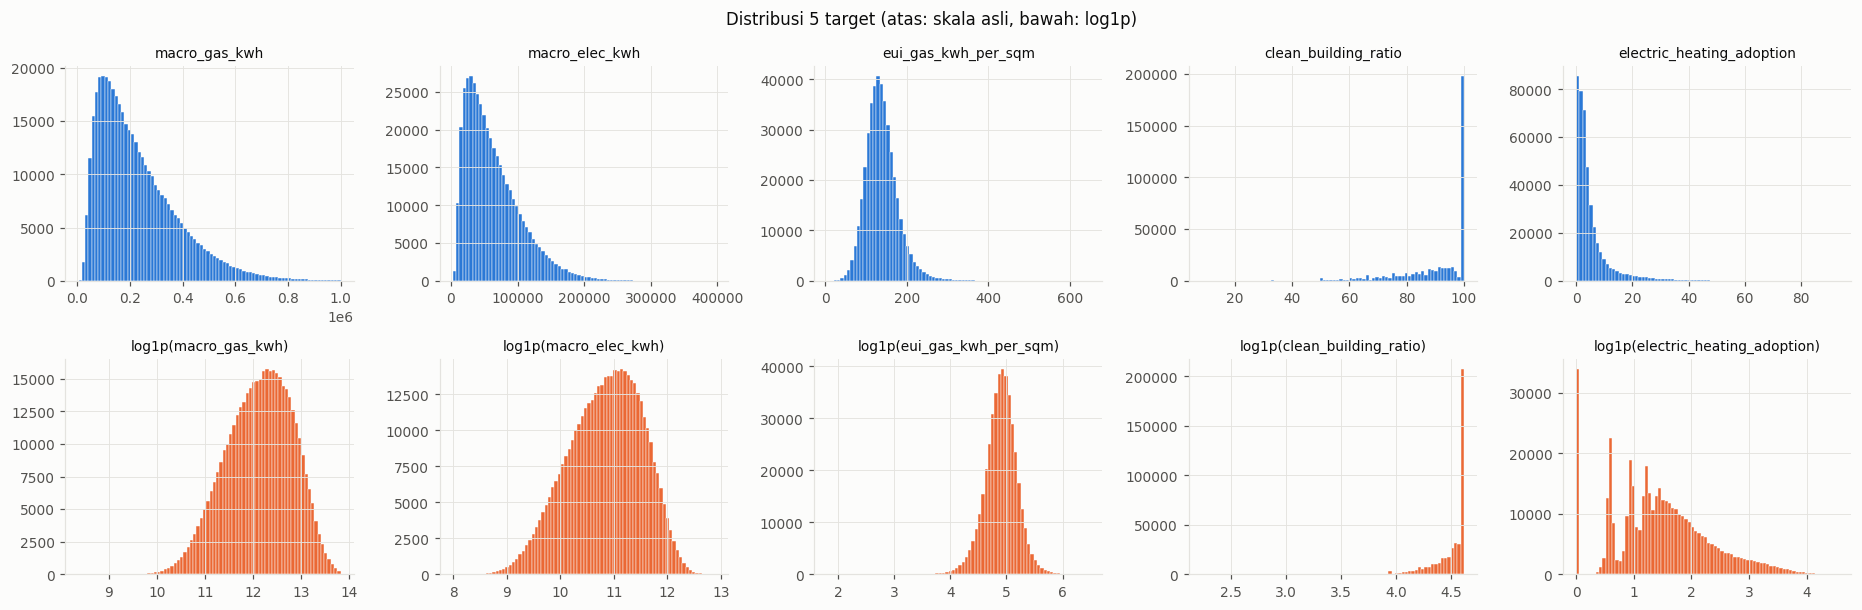

In [5]:
desc = train_raw[TARGETS].describe(percentiles=[.01, .5, .99]).T
desc["frozen_sigma"] = [SIGMA[t] for t in TARGETS]
display(desc.round(3))

fig, axes = plt.subplots(2, 5, figsize=(17, 5.6))
for i, t in enumerate(TARGETS):
    axes[0, i].hist(train_raw[t], bins=80, color=C1, edgecolor=SURF, linewidth=0.3)
    axes[0, i].set_title(t.replace("target_", ""), fontsize=9)
    v = np.log1p(train_raw[t])
    axes[1, i].hist(v, bins=80, color=C2, edgecolor=SURF, linewidth=0.3)
    axes[1, i].set_title("log1p(" + t.replace("target_", "") + ")", fontsize=9)
fig.suptitle("Distribusi 5 target (atas: skala asli, bawah: log1p)", color=INK); plt.tight_layout(); plt.show()

### 3.3 Korelasi target & fitur terkuat

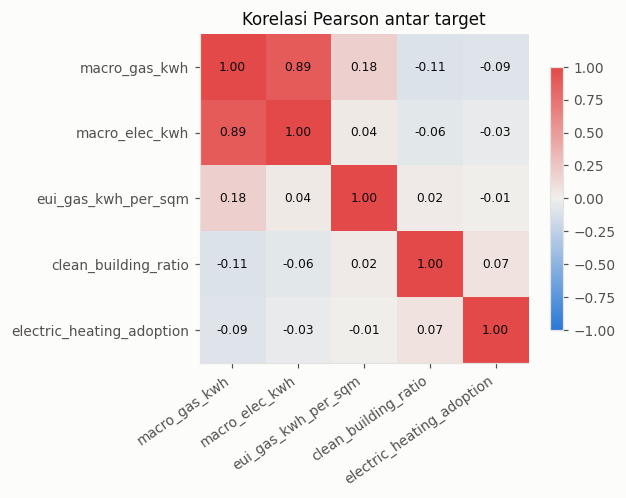

,macro_gas_kwh,macro_elec_kwh,eui_gas_kwh_per_sqm,clean_building_ratio,electric_heating_adoption
0,bld_dim_06 (0.919),bld_dim_12 (0.896),bld_dim_32 (0.186),socio_demog_011 (1.000),hvac_dist_02 (0.727)
1,bld_dim_07 (0.919),bld_dim_06 (0.889),bld_dim_20 (0.185),bld_dim_13 (0.953),socio_demog_035 (0.550)
2,bld_dim_08 (0.917),bld_dim_08 (0.886),socio_demog_073 (0.161),socio_demog_009 (0.952),socio_demog_057 (0.546)
3,bld_dim_03 (0.910),bld_dim_07 (0.884),socio_demog_082 (0.159),bld_dim_16 (0.940),socio_demog_055 (0.504)
4,bld_dim_04 (0.909),bld_dim_03 (0.883),env_climate_05 (0.154),socio_demog_003 (0.940),socio_demog_051 (0.470)


In [6]:
fig, ax = plt.subplots(figsize=(5.8, 4.6))
cm = train_raw[TARGETS].corr()
im = ax.imshow(cm, cmap=DIVERGING, vmin=-1, vmax=1)
short = [t.replace("target_", "") for t in TARGETS]
ax.set_xticks(range(5)); ax.set_xticklabels(short, rotation=35, ha="right"); ax.set_yticks(range(5)); ax.set_yticklabels(short)
for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", color=INK, fontsize=8)
ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Korelasi Pearson antar target"); plt.tight_layout(); plt.show()

num_cols = [c for c in feat_cols_raw if train_raw[c].dtype != object and c not in const_cols]
smp = train_raw.sample(min(80000, len(train_raw)), random_state=SEED)
top = {}
for t in TARGETS:
    s = smp[num_cols].corrwith(smp[t], method="spearman").abs().sort_values(ascending=False)
    top[t.replace("target_", "")] = [f"{k} ({v:.3f})" for k, v in s.head(5).items()]
display(pd.DataFrame(top))

### 3.4 Validasi split train/test & strategi CV

In [7]:
tr_sz, te_sz = set(train_raw.subzone_id), set(test_raw.subzone_id)
print("zone_region_id unik  train/test/overlap:", train_raw.zone_region_id.nunique(), test_raw.zone_region_id.nunique(),
      len(set(train_raw.zone_region_id) & set(test_raw.zone_region_id)))
print("subzone_id unik      train/test/overlap:", len(tr_sz), len(te_sz), len(tr_sz & te_sz))
actual_seen = test_raw.subzone_id.isin(tr_sz).mean()
allsz = np.concatenate([train_raw.subzone_id.values, test_raw.subzone_id.values])
rng = np.random.default_rng(SEED); sims = []
for _ in range(5):
    m = rng.random(len(allsz)) < len(test_raw) / len(allsz)
    seen = set(allsz[~m]); sims.append(np.mean([s in seen for s in allsz[m]]))
print(f"Proporsi baris test dengan subzone dikenal: aktual={actual_seen:.4f} | simulasi random-row-split={np.mean(sims):.4f} ± {np.std(sims):.4f}")
print("Baris per subzone (train):", train_raw.subzone_id.value_counts().describe().round(2).to_dict())

# adversarial validation
adv_cols = [c for c in num_cols if train_raw[c].dtype != object]
n_adv = min(100000, len(train_raw), len(test_raw))
adv = pd.concat([train_raw[adv_cols].sample(n_adv, random_state=SEED), test_raw[adv_cols].sample(n_adv, random_state=SEED)], ignore_index=True)
adv_y = np.r_[np.zeros(n_adv), np.ones(n_adv)]
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score
adv_p = cross_val_predict(lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=63, verbose=-1, random_state=SEED,
                                             n_jobs=N_THREADS, deterministic=True, force_col_wise=True),
                          adv, adv_y, cv=KFold(3, shuffle=True, random_state=SEED), method="predict_proba")[:, 1]
print(f"Adversarial validation AUC (train vs test): {roc_auc_score(adv_y, adv_p):.4f}")
del adv, adv_y, adv_p; _ = gc.collect()

zone_region_id unik  train/test/overlap: 330 329 329
subzone_id unik      train/test/overlap: 153508 110548 100871
Proporsi baris test dengan subzone dikenal: aktual=0.9186 | simulasi random-row-split=0.9177 ± 0.0006
Baris per subzone (train): {'count': 153508.0, 'mean': 2.8, 'std': 1.56, 'min': 1.0, '25%': 2.0, '50%': 3.0, '75%': 4.0, 'max': 14.0}
Adversarial validation AUC (train vs test): 0.5039


### 3.5 Struktur hierarkis subzone vs baris

In [8]:
multi = train_raw.subzone_id.map(train_raw.subzone_id.value_counts()) > 1
tmp = train_raw.loc[multi, num_cols + TARGETS + ["subzone_id"]]
within = (tmp[num_cols + TARGETS] - tmp.groupby("subzone_id")[num_cols + TARGETS].transform("mean")).std() / train_raw[num_cols + TARGETS].std()
sz_const = [c for c in num_cols if within[c] < 1e-6]
row_var = [c for c in num_cols if within[c] >= 1e-6]
print(f"Fitur konstan di dalam subzone (level-subzone, mis. sensus): {len(sz_const)} | fitur bervariasi per baris: {len(row_var)}")
print("Prefix fitur level-baris:", pd.Series([c.rsplit('_', 1)[0] for c in row_var]).value_counts().to_dict())
print("Rasio std-dalam-subzone / std-total untuk target:"); display(within[TARGETS].round(3).to_frame("within_ratio").T)
print("Subzone yang melintasi >1 zone:", int((train_raw.groupby("subzone_id").zone_region_id.nunique() > 1).sum()))
del tmp; _ = gc.collect()

Fitur konstan di dalam subzone (level-subzone, mis. sensus): 114 | fitur bervariasi per baris: 74
Prefix fitur level-baris: {'bld_dim': 41, 'socio_demog': 14, 'bld_era': 14, 'env_climate': 5}
Rasio std-dalam-subzone / std-total untuk target:


,target_macro_gas_kwh,target_macro_elec_kwh,target_eui_gas_kwh_per_sqm,target_clean_building_ratio,target_electric_heating_adoption
within_ratio,0.724,0.744,0.693,0.627,0.0


Subzone yang melintasi >1 zone: 0


### 3.6 Temuan kunci EDA

[1] max |gas - EUI*bld_dim_06| / gas = 7.75e-16
[2] clean formula exact match: 100.000% baris | NRMSE = 0.000000
[3] subzone dengan >1 nilai EH: 0 dari 153508 | min(rem - EH) = -3.46e-14 | proporsi rem == EH: 0.500


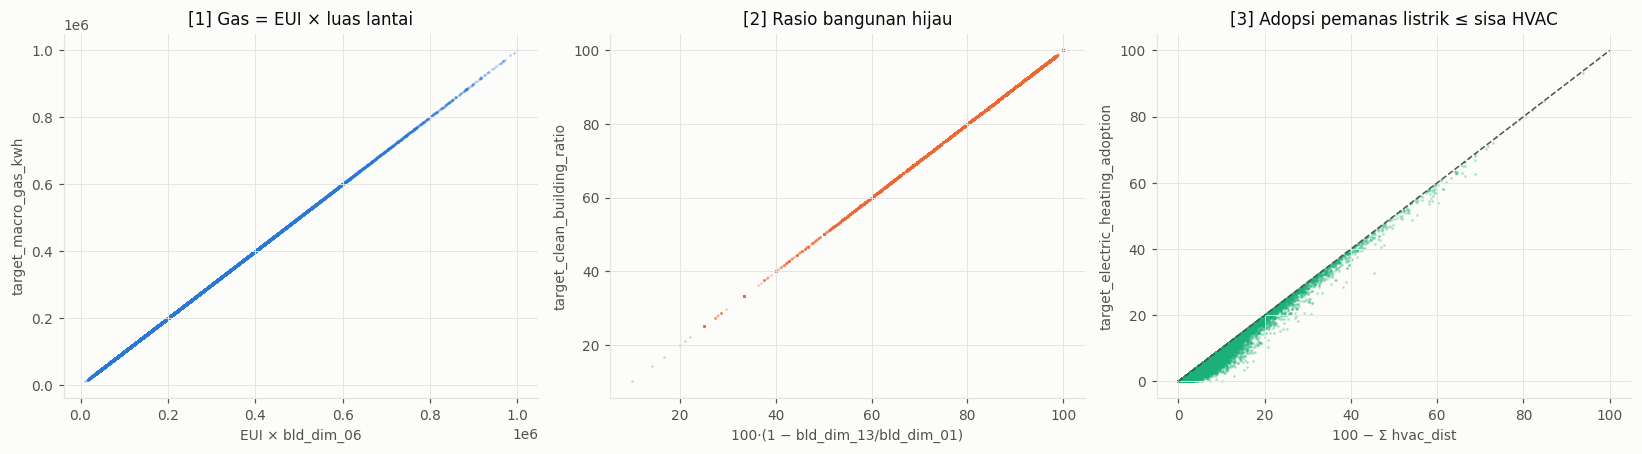

In [9]:
area = train_raw["bld_dim_06"]
gas_rel = (train_raw[G] - train_raw[U] * area).abs() / train_raw[G]
print(f"[1] max |gas - EUI*bld_dim_06| / gas = {gas_rel.max():.2e}")
clean_hat = np.round(100 * (1 - train_raw["bld_dim_13"] / train_raw["bld_dim_01"]), 2)
print(f"[2] clean formula exact match: {np.isclose(clean_hat, train_raw[CL], atol=1e-6).mean()*100:.3f}% baris | NRMSE = {nrmse(train_raw[CL], clean_hat, CL):.6f}")
eh_nuniq = train_raw.groupby("subzone_id")[EH].nunique()
rem = 100 - train_raw[HVAC].sum(axis=1)
print(f"[3] subzone dengan >1 nilai EH: {(eh_nuniq > 1).sum()} dari {len(eh_nuniq)} | min(rem - EH) = {(rem - train_raw[EH]).min():.2e}"
      f" | proporsi rem == EH: {np.isclose(rem, train_raw[EH], atol=1e-6).mean():.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
s = train_raw.sample(30000, random_state=SEED)
axes[0].scatter(s[U] * s["bld_dim_06"], s[G], s=3, color=C1, alpha=0.35, linewidths=0)
axes[0].set_xlabel("EUI × bld_dim_06"); axes[0].set_ylabel("target_macro_gas_kwh"); axes[0].set_title("[1] Gas = EUI × luas lantai")
axes[1].scatter(100 * (1 - s["bld_dim_13"] / s["bld_dim_01"]), s[CL], s=3, color=C2, alpha=0.35, linewidths=0)
axes[1].set_xlabel("100·(1 − bld_dim_13/bld_dim_01)"); axes[1].set_ylabel("target_clean_building_ratio"); axes[1].set_title("[2] Rasio bangunan hijau")
axes[2].scatter(100 - s[HVAC].sum(axis=1), s[EH], s=3, color=C3, alpha=0.35, linewidths=0)
lim = [0, 100]; axes[2].plot(lim, lim, color=INK2, linewidth=1, linestyle="--")
axes[2].set_xlabel("100 − Σ hvac_dist"); axes[2].set_ylabel("target_electric_heating_adoption"); axes[2].set_title("[3] Adopsi pemanas listrik ≤ sisa HVAC")
plt.tight_layout(); plt.show()
del s; _ = gc.collect()

## 4. Preprocessing

In [10]:
ERA_MAP = {"High (<0%)": 0, "Medium (0-6%)": 1, "Low (6-18%)": 2, "Very Low (>18%)": 3}

def preprocess(df):
    df = df.copy()
    df["bld_dim_18"] = df["bld_dim_18"].map(ERA_MAP).astype("float32")
    df["socio_demog_016"] = (df["socio_demog_016"] == "Urban").astype("float32")
    df["zone_code"] = df["zone_region_id"].str[4:].astype(int)
    df["subzone_code"] = df["subzone_id"].str[4:].astype(int)
    return df

train = preprocess(train_raw)
test = preprocess(test_raw)
FEATS = [c for c in train.columns if c not in {"id", "zone_region_id", "subzone_id", *TARGETS}
         and train[c].nunique(dropna=False) > 1]
print(f"Fitur dasar: {len(FEATS)} kolom numerik (termasuk zone_code & subzone_code; {len(const_cols)} kolom konstan dibuang)")

fold_id = np.zeros(len(train), dtype=int)
for k, (_, va) in enumerate(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(train)):
    fold_id[va] = k
print("Ukuran fold:", np.bincount(fold_id))

Y = {t: train[t].values.astype(np.float64) for t in TARGETS}
AREA_TR = train["bld_dim_06"].values.astype(np.float64)
AREA_TE = test["bld_dim_06"].values.astype(np.float64)
del train_raw; _ = gc.collect()

# Wadah prediksi semua model: OOF (train) dan test, per target
OOF = {t: {} for t in TARGETS}
TEST = {t: {} for t in TARGETS}

Fitur dasar: 192 kolom numerik (termasuk zone_code & subzone_code; 11 kolom konstan dibuang)
Ukuran fold: [85861 85861 85861 85860 85860]


### 4.1 Target deterministik: clean_building_ratio

In [11]:
def clean_ratio(df):
    return np.round(100.0 * (1.0 - df["bld_dim_13"].values / df["bld_dim_01"].values), 2)

OOF[CL]["formula"] = clean_ratio(train)
TEST[CL]["formula"] = clean_ratio(test)
print(f"NRMSE clean_building_ratio (train, formula): {nrmse(Y[CL], OOF[CL]['formula'], CL):.6f}")

NRMSE clean_building_ratio (train, formula): 0.000000


## 5. Rekayasa Fitur

In [12]:
def _div(a, b):
    a = np.asarray(a, dtype=np.float64); b = np.asarray(b, dtype=np.float64)
    with np.errstate(divide="ignore", invalid="ignore"):
        r = a / b
    r[~np.isfinite(r)] = np.nan
    return r.astype(np.float32)

ERA_C = [f"bld_era_{i:02d}" for i in range(2, 9)]     # hitungan era konstruksi
ERA_P = [f"bld_era_{i:02d}" for i in range(9, 16)]    # persentase era konstruksi
TYP_C = [f"bld_dim_{i}" for i in range(19, 31)]       # hitungan tipe bangunan
TYP_P = [f"bld_dim_{i}" for i in range(31, 43)]       # persentase tipe bangunan
RANK_COLS = ["bld_dim_03", "bld_dim_04", "bld_dim_05", "bld_dim_07", "bld_dim_08", "socio_demog_002", "bld_dim_12",
             "bld_dim_01", "bld_dim_02", "bld_dim_13", "bld_dim_17", "bld_dim_43", "bld_dim_14", "bld_dim_10",
             "env_climate_01", "env_climate_03", "env_climate_05"]

def _fe_ratio(al):
    o = {}
    A = al["bld_dim_06"].values
    for c in ["bld_dim_12", "bld_dim_01", "bld_dim_02", "bld_dim_13"]:
        o[f"area_per_{c[-2:]}"] = _div(A, al[c].values)
    for c in ["bld_dim_03", "bld_dim_04", "bld_dim_05", "bld_dim_07", "bld_dim_08", "socio_demog_002",
              "bld_dim_10", "bld_dim_14", "bld_dim_15", "bld_dim_16", "socio_demog_003"]:
        o[f"r_{c}_06"] = _div(al[c].values, A)
    o["r_07_08"] = _div(al["bld_dim_07"].values, al["bld_dim_08"].values)
    o["r_04_03"] = _div(al["bld_dim_04"].values, al["bld_dim_03"].values)
    o["r_05_03"] = _div(al["bld_dim_05"].values, al["bld_dim_03"].values)
    o["r_04_05"] = _div(al["bld_dim_04"].values, al["bld_dim_05"].values)
    o["r_sd002_03"] = _div(al["socio_demog_002"].values, al["bld_dim_03"].values)
    o["c_01_12"] = _div(al["bld_dim_01"].values, al["bld_dim_12"].values)
    o["c_02_12"] = _div(al["bld_dim_02"].values, al["bld_dim_12"].values)
    o["c_02_01"] = _div(al["bld_dim_02"].values, al["bld_dim_01"].values)
    o["c_13_12"] = _div(al["bld_dim_13"].values, al["bld_dim_12"].values)
    o["c_09_12"] = _div(al["bld_dim_09"].values, al["bld_dim_12"].values)
    o["a03_per_12"] = _div(al["bld_dim_03"].values, al["bld_dim_12"].values)
    o["a07_per_12"] = _div(al["bld_dim_07"].values, al["bld_dim_12"].values)
    o["a07_per_01"] = _div(al["bld_dim_07"].values, al["bld_dim_01"].values)
    o["sd002_per_12"] = _div(al["socio_demog_002"].values, al["bld_dim_12"].values)
    return pd.DataFrame(o)

def _fe_shares(al):
    o = {}
    se = al[ERA_C].sum(1).values
    for c in ERA_C:
        o[f"sh_{c}"] = _div(al[c].values, se)
    o["era_cnt_sum"] = se.astype(np.float32)
    o["era_cnt_idx"] = _div((al[ERA_C].values * np.arange(len(ERA_C))).sum(1), se)
    sp = al[ERA_P].sum(1).values
    o["era_pct_idx"] = _div((al[ERA_P].values * np.arange(len(ERA_P))).sum(1), sp)
    o["era_pct_sum"] = sp.astype(np.float32)
    st = al[TYP_C].sum(1).values
    for c in TYP_C:
        o[f"sh_{c}"] = _div(al[c].values, st)
    o["typ_cnt_sum"] = st.astype(np.float32)
    o["typ_cnt_frac02"] = _div(st, al["bld_dim_02"].values)
    o["typ_pct_sum"] = al[TYP_P].sum(1).values.astype(np.float32)
    return pd.DataFrame(o)

def _fe_group(al, key, pre, ratio):
    """Agregat fitur level-baris di dalam subzone/zone (fitur train+test)."""
    o = {}
    g = al.groupby(key, sort=False)
    o[f"{pre}_n"] = g[key].transform("size").values.astype(np.float32)
    for c in ["bld_dim_06", "bld_dim_12", "bld_dim_01", "bld_dim_02", "bld_dim_03", "bld_dim_07", "socio_demog_002"]:
        s = g[c].transform("sum").values
        o[f"{pre}_sum_{c}"] = s.astype(np.float32)
        o[f"{pre}_share_{c}"] = _div(al[c].values, s)
    o[f"{pre}_area_per_12"] = _div(o[f"{pre}_sum_bld_dim_06"], o[f"{pre}_sum_bld_dim_12"])
    o[f"{pre}_dev_area_per_12"] = _div(al["bld_dim_06"].values / al["bld_dim_12"].values, o[f"{pre}_area_per_12"])
    o[f"{pre}_area_rank"] = g["bld_dim_06"].rank(pct=True).values.astype(np.float32)
    for c in ratio.columns:
        m = ratio[c].groupby(al[key].values).transform("mean").values
        o[f"{pre}_mean_{c}"] = m.astype(np.float32)
        o[f"{pre}_dev_{c}"] = (ratio[c].values - m).astype(np.float32)
    for c in ["env_climate_01", "env_climate_03", "env_climate_05", "bld_dim_17"] + (["bld_dim_43"] if pre != "sz" else []):
        m = g[c].transform("mean").values
        o[f"{pre}_dev_{c}"] = (al[c].values - m).astype(np.float32)
    return pd.DataFrame(o)

def _fe_context(al, rat, sh, key, pre):
    """Konteks kelompok: rata-rata / rasio terhadap median / persentil fitur per-unit & rasio."""
    o = {}
    kv = al[key].values
    base = pd.concat([rat, sh], axis=1)
    cols_mean = ["area_per_12", "area_per_01", "area_per_02", "a03_per_12", "a07_per_12", "sd002_per_12",
                 "r_bld_dim_07_06", "r_bld_dim_04_06", "r_bld_dim_05_06", "r_bld_dim_08_06", "r_socio_demog_002_06",
                 "r_bld_dim_03_06", "c_01_12", "c_02_12", "c_13_12", "c_02_01", "era_cnt_idx", "era_pct_idx", "typ_cnt_frac02"]
    cols_mean += [c for c in sh.columns if c.startswith("sh_")]
    mn = base[cols_mean].groupby(kv).transform("mean")
    for c in cols_mean:
        o[f"{pre}_mean_{c}"] = mn[c].values.astype(np.float32)
    for c in ["area_per_12", "area_per_01", "a03_per_12", "a07_per_12", "sd002_per_12", "r_bld_dim_07_06",
              "r_bld_dim_04_06", "r_socio_demog_002_06", "r_bld_dim_05_06", "c_01_12", "era_cnt_idx", "era_pct_idx"]:
        med = base[c].groupby(kv).transform("median").values
        o[f"{pre}_rmed_{c}"] = _div(base[c].values, med)
        o[f"{pre}_rank_{c}"] = base[c].groupby(kv).rank(pct=True).values.astype(np.float32)
    for c in ["bld_dim_43", "bld_dim_17", "bld_dim_18", "bld_dim_09", "bld_dim_10", "socio_demog_005", "socio_demog_011", "socio_demog_014"]:
        m = al[c].groupby(kv).transform("mean").values
        o[f"{pre}_mean_{c}"] = m.astype(np.float32)
        o[f"{pre}_dev_{c}"] = (al[c].values - m).astype(np.float32)
    return pd.DataFrame(o)

def _fe_rank(al, key="zone_region_id", pre="zr"):
    """Persentil & z-score fitur level-baris di dalam zona."""
    o = {}
    kv = al[key].values
    g = al[RANK_COLS].groupby(kv)
    rk = g.rank(pct=True)
    mu = g.transform("mean"); sd = g.transform("std")
    for c in RANK_COLS:
        o[f"{pre}_rank_{c}"] = rk[c].values.astype(np.float32)
        o[f"{pre}_z_{c}"] = _div(al[c].values - mu[c].values, sd[c].values)
    return pd.DataFrame(o)

def build_features_eui_gas(train_df, test_df, F):
    """Set A (496 kolom, float32). Tidak memakai kolom target."""
    keep = F + ["subzone_id", "zone_region_id"]
    al = pd.concat([train_df[keep], test_df[keep]], ignore_index=True)
    for c in F:
        if al[c].dtype == np.float64:
            al[c] = al[c].astype(np.float32)
    parts = [al[F].astype(np.float32)]
    rat = _fe_ratio(al); parts.append(rat)
    sh = _fe_shares(al); parts.append(sh)
    parts.append(_fe_context(al, rat, sh, key="zone_region_id", pre="z2"))
    parts.append(_fe_rank(al))
    parts.append(_fe_context(al, rat, sh, key="subzone_id", pre="s2"))
    sel = rat[["area_per_12", "r_bld_dim_07_06", "r_bld_dim_04_06", "c_01_12"]]
    parts.append(_fe_group(al, "subzone_id", "sz", sel))
    parts.append(_fe_group(al, "zone_region_id", "zn", sel))
    X = pd.concat(parts, axis=1)
    n = len(train_df)
    return X.iloc[:n].reset_index(drop=True), X.iloc[n:].reset_index(drop=True)

In [13]:
_CNT = [f"bld_dim_{i:02d}" for i in [1, 2, 9, 13] + list(range(19, 31))]
_AREA = [f"bld_dim_{i:02d}" for i in [3, 4, 5, 6, 7, 8, 10, 14, 15, 16]]
_ERA = [f"bld_era_{i:02d}" for i in range(2, 16)]
_PCT = [f"bld_dim_{i}" for i in range(31, 44)]
_VARSOC = ["socio_demog_002", "socio_demog_003", "socio_demog_005", "socio_demog_006"] + \
          [f"socio_demog_{i:03d}" for i in range(7, 16)]

def _group_block(al, key, pre):
    """Agregat kolom bangunan level-baris per kunci kelompok (fitur train+test)."""
    out = {}
    n12 = al["bld_dim_12"].astype("float64"); a6 = al["bld_dim_06"].astype("float64")
    g = al.groupby(key)
    cnt = g["bld_dim_12"].transform("size")
    s12 = g["bld_dim_12"].transform("sum"); s6 = g["bld_dim_06"].transform("sum")
    s01 = g["bld_dim_01"].transform("sum"); s02 = g["bld_dim_02"].transform("sum")
    out[f"{pre}_cnt"] = cnt
    out[f"{pre}_s12"] = s12
    out[f"{pre}_sh12"] = n12 / s12
    if pre != "cell":
        out[f"{pre}_sh6"] = a6 / s6
    out[f"{pre}_apm"] = s6 / s12
    out[f"{pre}_apm_rel"] = (a6 / n12) / (s6 / s12)
    out[f"{pre}_n12_rel"] = n12 / (s12 / cnt)
    out[f"{pre}_r1201"] = s12 / s01
    out[f"{pre}_r1202"] = s12 / s02
    for c in ["bld_dim_23", "bld_dim_24", "bld_dim_20", "bld_dim_13"]:
        out[f"{pre}_{c}_pm"] = g[c].transform("sum") / s12
    for c in ["bld_dim_37", "bld_dim_32", "bld_dim_43", "bld_dim_17"]:
        m = g[c].transform("mean")
        out[f"{pre}_{c}_mean"] = m
        out[f"{pre}_{c}_dev"] = al[c] - m
    return out

def build_features_elec(train_df, test_df, F):
    """Set B (426 kolom, float32). Tidak memakai kolom target."""
    keys = ["subzone_id", "zone_region_id"]
    al = pd.concat([train_df[F + keys], test_df[F + keys]], ignore_index=True)
    for c in F:
        al[c] = al[c].astype("float32")
    n12 = al["bld_dim_12"].astype("float64"); n01 = al["bld_dim_01"].astype("float64")
    n02 = al["bld_dim_02"].astype("float64"); a6 = al["bld_dim_06"].astype("float64")
    r = {}
    for c in _AREA + _CNT:
        r[f"r12_{c}"] = al[c] / n12
    for c in ["bld_dim_06", "bld_dim_03", "bld_dim_13", "bld_dim_23", "bld_dim_24", "bld_dim_20", "bld_dim_14"]:
        r[f"r01_{c}"] = al[c] / n01
    s1930 = al[[f"bld_dim_{i}" for i in range(19, 31)]].sum(1)
    r["s1930"] = s1930
    for i in range(19, 31):
        r[f"sh_{i}"] = al[f"bld_dim_{i}"] / s1930.replace(0, np.nan)
    r["d12_01"] = n12 - n01; r["d12_02"] = n12 - n02; r["d02_01"] = n02 - n01
    r["r12_s1930"] = s1930 / n12
    r["log_n12"] = np.log(n12)
    r["a6_per_m_log"] = np.log(a6 / n12)
    r.update(_group_block(al, "subzone_id", "sz"))
    r.update(_group_block(al, "zone_region_id", "zn"))
    b1 = pd.DataFrame(r).astype("float32")
    r = {}
    ck = al["env_climate_01"].round(4).astype(str) + "|" + al["env_climate_02"].round(4).astype(str)
    ck = pd.Series(pd.factorize(ck)[0], index=al.index)
    r.update(_group_block(al, ck, "cell"))
    r["cell_nsz"] = al.groupby(ck)["subzone_code"].transform("nunique")
    g = al.groupby("subzone_id")
    for c in _ERA + _PCT + _VARSOC:
        m = g[c].transform("mean"); r[f"sz2_{c}_mean"] = m; r[f"sz2_{c}_dev"] = al[c] - m
    cnt2 = [f"bld_era_{i:02d}" for i in range(2, 9)] + ["socio_demog_002", "socio_demog_003", "socio_demog_006",
                                                         "socio_demog_007", "socio_demog_008", "socio_demog_009",
                                                         "socio_demog_010", "socio_demog_127"]
    for c in cnt2:
        r[f"r12_{c}"] = al[c] / n12
        r[f"r01_{c}"] = al[c] / n01
    se = al[[f"bld_era_{i:02d}" for i in range(2, 9)]].sum(1)
    r["era_cnt_sum"] = se
    for i in range(2, 9):
        r[f"era_sh_{i}"] = al[f"bld_era_{i:02d}"] / se.replace(0, np.nan)
    r["r_sd002_a6"] = al["socio_demog_002"] / al["bld_dim_06"]
    b2 = pd.DataFrame(r).astype("float32")
    X = pd.concat([al[F], b1, b2], axis=1)
    ntr = len(train_df)
    return X.iloc[:ntr].reset_index(drop=True), X.iloc[ntr:].reset_index(drop=True)

In [14]:
def recover_household_count(H, max_n=5000, tol=1e-6):
    """N terkecil sehingga semua persentase hvac (n x 10, float64) x N/100 bernilai bulat (jumlah rumah tangga subzone)."""
    H = np.asarray(H, dtype=np.float64)
    out = np.zeros(len(H), dtype=np.int64); todo = np.ones(len(H), dtype=bool)
    for N in range(1, max_n + 1):
        idx = np.flatnonzero(todo)
        x = H[idx] * N / 100.0
        ok = np.abs(x - np.round(x)).max(1) < tol
        out[idx[ok]] = N; todo[idx[ok]] = False
        if not todo.any():
            break
    return out

def _divn(a, b):
    a = np.asarray(a, dtype=np.float64); b = np.asarray(b, dtype=np.float64)
    with np.errstate(divide="ignore", invalid="ignore"):
        r = a / b
    r[~np.isfinite(r)] = np.nan
    return r

def build_nfeat23(train_df, test_df):
    """Set N23: jumlah rumah tangga N (kisi hvac) + rasio cakupan meter subzone + estimasi rumah tangga per postcode (tanpa label)."""
    cols = ["subzone_id", "bld_dim_01", "bld_dim_02", "bld_dim_06", "bld_dim_12"] + HVAC
    al = pd.concat([train_df[cols], test_df[cols]], ignore_index=True)
    for c in HVAC:
        al[c] = al[c].astype(np.float64)
    g = al.groupby("subzone_id", sort=False)
    szc = g[HVAC].first(); N = pd.Series(recover_household_count(szc.values).astype(np.float64), index=szc.index)
    Nr = al["subzone_id"].map(N).values
    n12 = al["bld_dim_12"].values.astype(np.float64); n01 = al["bld_dim_01"].values.astype(np.float64)
    n02 = al["bld_dim_02"].values.astype(np.float64); a6 = al["bld_dim_06"].values.astype(np.float64)
    s12 = g["bld_dim_12"].transform("sum").values.astype(np.float64); s01 = g["bld_dim_01"].transform("sum").values.astype(np.float64)
    s02 = g["bld_dim_02"].transform("sum").values.astype(np.float64); s06 = g["bld_dim_06"].transform("sum").values.astype(np.float64)
    nrow = g["bld_dim_12"].transform("size").values.astype(np.float64)
    h02 = al["hvac_dist_02"].values; rem = 100.0 - al[HVAC].sum(1).values
    o = {}
    o["N_hh"] = Nr; o["N_per_row"] = Nr / nrow; o["N_rem_cnt"] = Nr * rem / 100.0; o["N_gas_cnt"] = Nr * h02 / 100.0
    o["cov12"] = s12 / Nr; o["cov01"] = s01 / Nr; o["cov02"] = s02 / Nr; o["area_per_hh_oa"] = s06 / Nr
    o["cov12_gas"] = s12 / np.maximum(Nr * h02 / 100.0, 1.0)
    o["hh_est_12"] = n12 * Nr / s12; o["hh_est_02"] = n02 * Nr / s02; o["hh_est_01"] = n01 * Nr / s01; o["hh_est_06"] = a6 * Nr / s06
    o["hh_est_mix"] = np.sqrt(o["hh_est_12"] * o["hh_est_02"])
    o["gashh_est"] = n12 * (Nr * h02 / 100.0) / s12
    o["gas_share_est02"] = n12 * s02 / (Nr * n02); o["gas_share_est01"] = n12 * s01 / (Nr * n01); o["gas_share_est06"] = n12 * s06 / (Nr * a6)
    o["log_hhest02_over_n12"] = np.log(o["hh_est_02"] / n12); o["log_hhest01_over_n12"] = np.log(o["hh_est_01"] / n12)
    o["log_hhest06_over_n12"] = np.log(o["hh_est_06"] / n12)
    o["nonGas_est"] = np.maximum(o["hh_est_02"] - n12, 0.0); o["remHH_est"] = o["hh_est_02"] * rem / 100.0
    X = pd.DataFrame(o).replace([np.inf, -np.inf], np.nan).astype(np.float32)
    n = len(train_df)
    return X.iloc[:n].reset_index(drop=True), X.iloc[n:].reset_index(drop=True)

NFEAT31_COLS = ["N_hh", "logN_hh", "cov12", "cov02", "cov01", "covrows", "area_per_hh", "gas_hh", "rem_hh", "s12_per_gashh",
                "s02_per_gashh", "hh_uncovered12", "hh_uncovered02", "cov12_x_h02", "sh12_N", "sh02_N", "sh01_N", "area_N",
                "exp_gasm12", "exp_gasm02", "exp_gasm06", "imp_hh12", "imp_hh02", "area_per_imphh12", "area_per_imphh02",
                "n12_per_exp_gasm02", "n12_per_exp_gasm06", "n02_per_exp_gasm12", "gasfrac_imp12", "n13_sh_N", "s13_per_N"]

def build_nfeat31(train_df, test_df):
    """Set N31: varian fitur berbasis N (cakupan, rumah tangga bergas, ekspektasi meter gas per postcode). Tanpa label."""
    need = ["subzone_id", "bld_dim_01", "bld_dim_02", "bld_dim_06", "bld_dim_12", "bld_dim_13"] + HVAC
    al = pd.concat([train_df[need], test_df[need]], ignore_index=True)
    for c in HVAC:
        al[c] = al[c].astype(np.float64)
    g = al.groupby("subzone_id", sort=False)
    H = g[HVAC].first()
    N = al["subzone_id"].map(pd.Series(recover_household_count(H.values), index=H.index)).values.astype(np.float64)
    n12 = al["bld_dim_12"].values.astype(np.float64); n02 = al["bld_dim_02"].values.astype(np.float64)
    n01 = al["bld_dim_01"].values.astype(np.float64); a6 = al["bld_dim_06"].values.astype(np.float64)
    n13 = al["bld_dim_13"].values.astype(np.float64)
    s12 = g["bld_dim_12"].transform("sum").values.astype(np.float64); s02 = g["bld_dim_02"].transform("sum").values.astype(np.float64)
    s01 = g["bld_dim_01"].transform("sum").values.astype(np.float64); s06 = g["bld_dim_06"].transform("sum").values.astype(np.float64)
    s13 = g["bld_dim_13"].transform("sum").values.astype(np.float64); nrow = g["bld_dim_12"].transform("size").values.astype(np.float64)
    h02 = al["hvac_dist_02"].values.astype(np.float64)
    rem = np.clip(100.0 - al[HVAC].sum(axis=1).values, 0, None)
    gas_hh = N * h02 / 100.0
    o = {}
    o["N_hh"] = N; o["logN_hh"] = np.log(N)
    o["cov12"] = _divn(s12, N); o["cov02"] = _divn(s02, N); o["cov01"] = _divn(s01, N); o["covrows"] = _divn(nrow, N)
    o["area_per_hh"] = _divn(s06, N); o["gas_hh"] = gas_hh; o["rem_hh"] = N * rem / 100.0
    o["s12_per_gashh"] = _divn(s12, gas_hh); o["s02_per_gashh"] = _divn(s02, gas_hh)
    o["hh_uncovered12"] = N - s12; o["hh_uncovered02"] = N - s02; o["cov12_x_h02"] = _divn(s12, N) * h02 / 100.0
    o["sh12_N"] = _divn(n12, N); o["sh02_N"] = _divn(n02, N); o["sh01_N"] = _divn(n01, N); o["area_N"] = _divn(a6, N)
    o["exp_gasm12"] = gas_hh * _divn(n12, s12); o["exp_gasm02"] = gas_hh * _divn(n02, s02); o["exp_gasm06"] = gas_hh * _divn(a6, s06)
    o["imp_hh12"] = _divn(n12 * N, s12); o["imp_hh02"] = _divn(n02 * N, s02)
    o["area_per_imphh12"] = _divn(a6, o["imp_hh12"]); o["area_per_imphh02"] = _divn(a6, o["imp_hh02"])
    o["n12_per_exp_gasm02"] = _divn(n12, o["exp_gasm02"]); o["n12_per_exp_gasm06"] = _divn(n12, o["exp_gasm06"])
    o["n02_per_exp_gasm12"] = _divn(n02, o["exp_gasm12"]); o["gasfrac_imp12"] = _divn(o["exp_gasm12"], o["imp_hh02"])
    o["n13_sh_N"] = _divn(n13, N); o["s13_per_N"] = _divn(s13, N)
    F = pd.DataFrame(o)[NFEAT31_COLS].astype(np.float32)
    n = len(train_df)
    return F.iloc[:n].reset_index(drop=True), F.iloc[n:].reset_index(drop=True)

def eh_lookup_feats(subzone_tr, eh_tr, subzone_pred, N_tr, N_pred, rem_tr, rem_pred, fold_tr=None):
    """Fitur EH level-subzone (nested): baris prediksi -> EH dari baris berlabel; baris berlabel (fold_tr diberikan) -> EH hanya dari
    baris berlabel fold LAIN, sehingga karakter seen/unseen sama dengan baris prediksi. NaN bila tidak ada lookup."""
    def feats(eh, N, rem):
        other = np.clip(rem - eh, 0, None)
        return np.column_stack([eh, N * eh / 100.0, N * other / 100.0, other, _divn(eh, rem)]).astype(np.float32)
    subzone_tr = np.asarray(subzone_tr); eh_tr = np.asarray(eh_tr, dtype=np.float64)
    lut = pd.Series(eh_tr).groupby(subzone_tr).first()
    eh_pred = pd.Series(np.asarray(subzone_pred)).map(lut).values.astype(np.float64)
    eh_lab = np.full(len(subzone_tr), np.nan)
    if fold_tr is not None:
        fold_tr = np.asarray(fold_tr)
        for j in np.unique(fold_tr):
            m = fold_tr == j
            lut_j = pd.Series(eh_tr[~m]).groupby(subzone_tr[~m]).first()
            eh_lab[m] = pd.Series(subzone_tr[m]).map(lut_j).values
    return feats(eh_lab, np.asarray(N_tr, float), np.asarray(rem_tr, float)), feats(eh_pred, np.asarray(N_pred, float), np.asarray(rem_pred, float))

## 6. Model EUI & Gas (LightGBM)

In [15]:
LGB_EUI_BASE = dict(objective="regression", learning_rate=0.05, num_leaves=127, min_data_in_leaf=200,
                    feature_fraction=0.3, bagging_fraction=0.8, bagging_freq=1, lambda_l2=10.0,
                    max_bin=255, feature_pre_filter=False, deterministic=True, force_col_wise=True, verbose=-1,
                    seed=SEED, num_threads=N_THREADS)
# target: eui | sqrteui | gas ;  wpow: bobot sampel = luas ** wpow ; seed = SEED + i
EUI_MODELS = [
    dict(name="sqrteui_w1",   target="sqrteui", wpow=1.0,  rounds=2000, params=dict(seed=SEED + 1)),
    dict(name="eui_gamma_w1", target="eui",     wpow=1.0,  rounds=1700, params=dict(seed=SEED + 2, objective="gamma")),
    dict(name="gas_wm05",     target="gas",     wpow=-0.5, rounds=2300, params=dict(seed=SEED + 3)),
    dict(name="eui_w05",      target="eui",     wpow=0.5,  rounds=1900, params=dict(seed=SEED + 5)),
    dict(name="gas_w05",      target="gas",     wpow=0.5,  rounds=2000, params=dict(seed=SEED + 7)),
]
_FWD = {"eui": lambda y, a: y, "sqrteui": lambda y, a: np.sqrt(y), "gas": lambda y, a: y * a}
_INV = {"eui": lambda p, a: p, "sqrteui": lambda p, a: p ** 2, "gas": lambda p, a: p / a}

XA_tr, XA_te = build_features_eui_gas(train, test, FEATS)
COLS_A = list(XA_tr.columns)
XA_tr = np.ascontiguousarray(XA_tr.values, dtype=np.float32); XA_te = np.ascontiguousarray(XA_te.values, dtype=np.float32)
_ = gc.collect()
print("Set fitur A:", XA_tr.shape, XA_te.shape)

def run_eui_lgb():
    area32 = AREA_TR.astype(np.float32).astype(np.float64); area32_te = AREA_TE.astype(np.float32).astype(np.float64)
    y = Y[U]
    out = {}
    for M in EUI_MODELS:
        out[f"{M['name']}_oof"] = np.zeros(len(y)); out[f"{M['name']}_test"] = np.zeros(len(XA_te))
    imp = np.zeros(len(COLS_A))
    for k in range(N_FOLDS):
        itr, iva = np.where(fold_id != k)[0], np.where(fold_id == k)[0]
        ds = lgb.Dataset(XA_tr[itr], label=y[itr], weight=np.ones(len(itr)), feature_name=COLS_A, free_raw_data=True,
                         params={"max_bin": 255, "feature_pre_filter": False, "deterministic": True, "force_col_wise": True,
                                 "verbose": -1, "num_threads": N_THREADS}).construct()
        for M in EUI_MODELS:
            t0 = time.time()
            w = area32[itr] ** M["wpow"] if M["wpow"] else np.ones(len(itr))
            P = dict(LGB_EUI_BASE); P.update(M["params"])
            # set_field (bukan set_weight): set_weight mengabaikan vektor bobot all-ones sehingga bobot lama tertinggal
            ds.set_label(_FWD[M["target"]](y[itr], area32[itr])); ds.set_field("weight", (w / w.mean()).astype(np.float32))
            m = lgb.train(P, ds, R(M["rounds"]))
            pv = _INV[M["target"]](m.predict(XA_tr[iva], num_threads=N_THREADS), area32[iva])
            pt = _INV[M["target"]](m.predict(XA_te, num_threads=N_THREADS), area32_te)
            out[f"{M['name']}_oof"][iva] = pv; out[f"{M['name']}_test"] += pt / N_FOLDS
            if M["name"] == "sqrteui_w1":
                imp += m.feature_importance("gain") / N_FOLDS
            print(f"  fold {k} {M['name']:<13} EUI {nrmse(y[iva], pv, U):.5f} | gas {nrmse(Y[G][iva], pv * AREA_TR[iva], G):.5f} "
                  f"({time.time() - t0:.0f}s)", flush=True)
            del m; gc.collect()
        del ds; gc.collect()
    out["importance"] = imp
    return out

res_eui = cached("lgb_eui_gas_v2", run_eui_lgb)
for M in EUI_MODELS:
    n = M["name"]
    OOF[U][f"lgb_{n}"] = res_eui[f"{n}_oof"];            TEST[U][f"lgb_{n}"] = res_eui[f"{n}_test"]
    OOF[G][f"lgb_{n}"] = res_eui[f"{n}_oof"] * AREA_TR;  TEST[G][f"lgb_{n}"] = res_eui[f"{n}_test"] * AREA_TE
summary = pd.DataFrame({n.replace("lgb_", ""): {"EUI": nrmse(Y[U], OOF[U][n], U), "gas": nrmse(Y[G], OOF[G][n], G)} for n in OOF[U]}).T
display(summary.round(5))

Set fitur A: (429303, 496) (183987, 496)
[cache] lgb_eui_gas_v2 dimuat dari artifacts\lgb_eui_gas_v2.npz


,EUI,gas
sqrteui_w1,0.66033,0.25001
eui_gamma_w1,0.66055,0.25027
gas_wm05,0.66721,0.25281
eui_w05,0.66122,0.25067
gas_w05,0.67813,0.25324


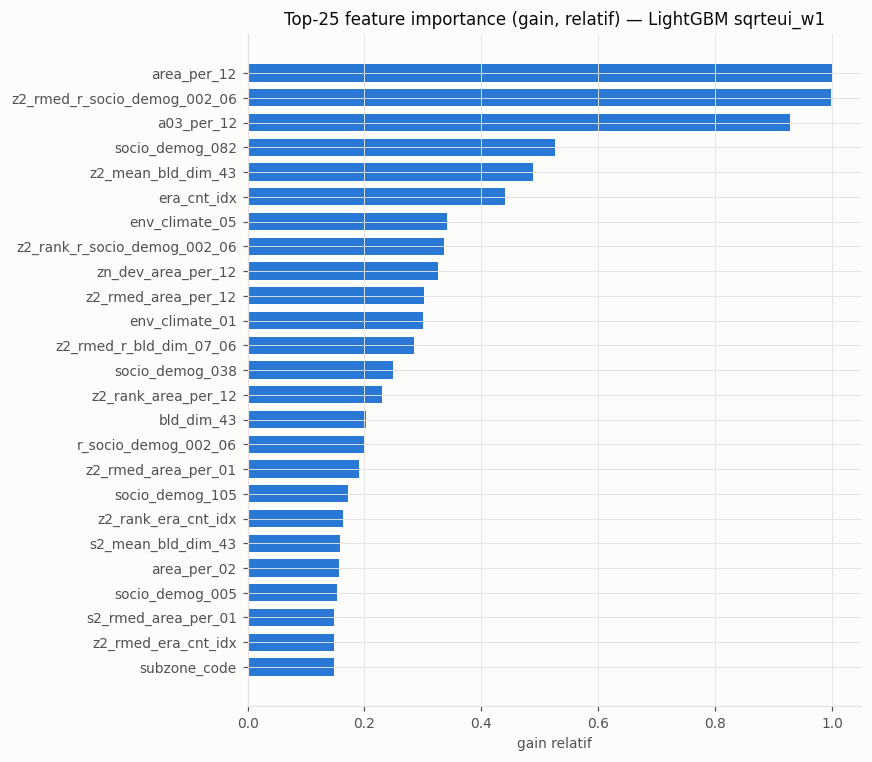

In [16]:
imp = pd.Series(res_eui["importance"], index=COLS_A).sort_values(ascending=False).head(25)[::-1]
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(imp.index, imp.values / imp.values.max(), color=C1, height=0.7)
ax.set_title("Top-25 feature importance (gain, relatif) — LightGBM sqrteui_w1"); ax.set_xlabel("gain relatif")
plt.tight_layout(); plt.show()

### 6.1 LightGBM gas per meter (Poisson + linear tree, 2 seed) & listrik per meter pada set A

In [17]:
LGB_ELEC_BASE = dict(objective="poisson", learning_rate=0.03, num_leaves=55, max_depth=8, min_data_in_leaf=150,
                     feature_fraction=0.3, bagging_fraction=0.9, bagging_freq=1, lambda_l2=30.0, lambda_l1=0.05,
                     min_sum_hessian_in_leaf=0.1, max_bin=255, verbose=-1, deterministic=True, force_col_wise=True)
# kind -> (label, bobot, invers ke target yang dinilai):  gpm = gas per meter / 1e3 ; elec_pm = listrik per meter / 1e3
# seeds: prediksi model fold dirata-rata atas daftar seed (bagging seed untuk anggota linear-tree yang variansnya tinggi)
EXTRA_LGB = {
    "gpm_lin_pois":    dict(base="eui",  kind="gpm",     rounds=3500, seeds=[SEED + 45, SEED + 245],
                            params=dict(objective="poisson", linear_tree=True, linear_lambda=1.0)),
    "gpm_lin_pois_el": dict(base="eui",  kind="gpm",     rounds=3000, seeds=[SEED + 47, SEED + 147],
                            params=dict(objective="poisson", linear_tree=True, linear_lambda=1.0)),
    "elec_pm_egfeat":  dict(base="elec", kind="elec_pm", rounds=6500, seeds=[SEED + 22], params=dict()),
}

def run_extra_lgb(names, X_tr, X_te, cols):
    """Anggota LightGBM tambahan pada satu set fitur. Prediksi EUI tiap model fold dibatasi maksimum EUI data latih fold
    tersebut (linear tree dapat meledak pada beberapa baris dengan banyak NaN)."""
    area32 = AREA_TR.astype(np.float32).astype(np.float64); area32_te = AREA_TE.astype(np.float32).astype(np.float64)
    n12 = train["bld_dim_12"].values.astype(np.float64); n12_te = test["bld_dim_12"].values.astype(np.float64)
    out = {}
    for name in names:
        M = EXTRA_LGB[name]
        P = dict(LGB_EUI_BASE if M["base"] == "eui" else LGB_ELEC_BASE); P.update(M["params"]); P["num_threads"] = N_THREADS
        if M["kind"] == "gpm":
            lab, w = Y[U] * area32 / n12 / 1e3, n12
            inv = lambda p, A, N: p * N * 1e3 / A
        else:
            lab, w = Y[E] / n12 / 1e3, n12
            inv = lambda p, A, N: p * N * 1e3
        oof = np.zeros(len(lab)); tst = np.zeros(len(X_te))
        for k in range(N_FOLDS):
            t0 = time.time()
            itr, iva = np.where(fold_id != k)[0], np.where(fold_id == k)[0]
            pv, pt = np.zeros(len(iva)), np.zeros(len(X_te))
            for sd in M["seeds"]:
                ds = lgb.Dataset(np.ascontiguousarray(X_tr[itr]), label=lab[itr], weight=(w[itr] / w[itr].mean()).astype(np.float32),
                                 feature_name=list(cols), free_raw_data=True,
                                 params={"max_bin": 255, "feature_pre_filter": False, "verbose": -1, "num_threads": N_THREADS,
                                         **({"linear_tree": True} if P.get("linear_tree") else {})})
                m = lgb.train(dict(P, seed=sd), ds, R(M["rounds"])); del ds; gc.collect()
                pv_s = inv(m.predict(np.ascontiguousarray(X_tr[iva]), num_threads=N_THREADS), area32[iva], n12[iva])
                pt_s = inv(m.predict(X_te, num_threads=N_THREADS), area32_te, n12_te)
                if M["kind"] == "gpm":
                    cap = Y[U][itr].max(); pv_s, pt_s = np.minimum(pv_s, cap), np.minimum(pt_s, cap)
                pv += pv_s / len(M["seeds"]); pt += pt_s / len(M["seeds"])
                del m; gc.collect()
            oof[iva] = pv; tst += pt / N_FOLDS
            tgt = U if M["kind"] == "gpm" else E
            print(f"  fold {k} {name:<16} {tgt.replace('target_', '')} NRMSE {nrmse(Y[tgt][iva], pv, tgt):.5f} ({time.time() - t0:.0f}s)", flush=True)
        out[f"{name}_oof"] = oof; out[f"{name}_test"] = tst
    return out

res_xa = cached("lgb_extra_setA_v3", lambda: run_extra_lgb(["gpm_lin_pois", "elec_pm_egfeat"], XA_tr, XA_te, COLS_A))
OOF[U]["lgb_gpm_lin_pois"] = res_xa["gpm_lin_pois_oof"];           TEST[U]["lgb_gpm_lin_pois"] = res_xa["gpm_lin_pois_test"]
OOF[G]["lgb_gpm_lin_pois"] = res_xa["gpm_lin_pois_oof"] * AREA_TR; TEST[G]["lgb_gpm_lin_pois"] = res_xa["gpm_lin_pois_test"] * AREA_TE
OOF[E]["lgb_elec_pm_setA"] = res_xa["elec_pm_egfeat_oof"];          TEST[E]["lgb_elec_pm_setA"] = res_xa["elec_pm_egfeat_test"]
print(f"gpm_lin_pois OOF: EUI {nrmse(Y[U], OOF[U]['lgb_gpm_lin_pois'], U):.5f} | gas {nrmse(Y[G], OOF[G]['lgb_gpm_lin_pois'], G):.5f}"
      f" || elec_pm (set A) OOF: {nrmse(Y[E], OOF[E]['lgb_elec_pm_setA'], E):.5f}")

  fold 0 gpm_lin_pois     eui_gas_kwh_per_sqm NRMSE 0.65541 (370s)
  fold 1 gpm_lin_pois     eui_gas_kwh_per_sqm NRMSE 0.65575 (374s)
  fold 2 gpm_lin_pois     eui_gas_kwh_per_sqm NRMSE 0.65238 (411s)
  fold 3 gpm_lin_pois     eui_gas_kwh_per_sqm NRMSE 0.64849 (407s)
  fold 4 gpm_lin_pois     eui_gas_kwh_per_sqm NRMSE 0.65220 (410s)
  fold 0 elec_pm_egfeat   macro_elec_kwh NRMSE 0.31927 (189s)
  fold 1 elec_pm_egfeat   macro_elec_kwh NRMSE 0.32022 (193s)
  fold 2 elec_pm_egfeat   macro_elec_kwh NRMSE 0.32039 (195s)
  fold 3 elec_pm_egfeat   macro_elec_kwh NRMSE 0.31722 (194s)
  fold 4 elec_pm_egfeat   macro_elec_kwh NRMSE 0.31555 (194s)
[lgb_extra_setA_v3] selesai dalam 48.9 menit
gpm_lin_pois OOF: EUI 0.65285 | gas 0.24670 || elec_pm (set A) OOF: 0.31854


## 7. Model Listrik (LightGBM + MLP Poisson)

In [18]:
LGB_ELEC = dict(objective="poisson", learning_rate=0.03, num_leaves=55, max_depth=8, min_data_in_leaf=150,
                feature_fraction=0.3, bagging_fraction=0.9, bagging_freq=1, lambda_l2=30.0, lambda_l1=0.05,
                min_sum_hessian_in_leaf=0.1, max_bin=255, verbose=-1, seed=SEED, deterministic=True, force_col_wise=True,
                num_threads=N_THREADS)
ELEC_ROUNDS = 5500
RATE_SCALE = 1e3

XB_tr, XB_te = build_features_elec(train, test, FEATS)
COLS_B = list(XB_tr.columns)
print("Set fitur B:", XB_tr.shape, XB_te.shape)

def run_elec_lgb():
    Xtr = np.ascontiguousarray(XB_tr.to_numpy(dtype=np.float32)); Xte = np.ascontiguousarray(XB_te.to_numpy(dtype=np.float32))
    y = Y[E]; n12 = train["bld_dim_12"].values.astype(np.float64); n12_te = test["bld_dim_12"].values.astype(np.float64)
    rate = y / n12 / RATE_SCALE
    oof = np.zeros(len(y)); tst = np.zeros(len(Xte))
    for k in range(N_FOLDS):
        t0 = time.time()
        itr, iva = np.where(fold_id != k)[0], np.where(fold_id == k)[0]
        m = lgb.train(LGB_ELEC, lgb.Dataset(Xtr[itr], rate[itr], weight=n12[itr], feature_name=COLS_B), R(ELEC_ROUNDS))
        oof[iva] = m.predict(Xtr[iva], num_threads=N_THREADS) * n12[iva] * RATE_SCALE
        tst += m.predict(Xte, num_threads=N_THREADS) * n12_te * RATE_SCALE / N_FOLDS
        print(f"  fold {k} elec-LGB NRMSE {nrmse(y[iva], oof[iva], E):.5f} ({time.time() - t0:.0f}s)", flush=True)
        del m; gc.collect()
    return {"oof": oof, "test": tst}

res_el_lgb = cached("lgb_elec_poisson", run_elec_lgb)
OOF[E]["lgb_poisson_pm"] = res_el_lgb["oof"]; TEST[E]["lgb_poisson_pm"] = res_el_lgb["test"]
print(f"elec LGB Poisson per-meter OOF NRMSE: {nrmse(Y[E], res_el_lgb['oof'], E):.5f}")

Set fitur B: (429303, 426) (183987, 426)
[cache] lgb_elec_poisson dimuat dari artifacts\lgb_elec_poisson.npz
elec LGB Poisson per-meter OOF NRMSE: 0.31891


In [19]:
import torch.nn as nn

def rank_gauss(X, nq=2000):
    """Peta kuantil empiris -> N(0,1) per kolom, dipasang pada fitur train+test (tanpa label). NaN/inf -> 0."""
    out = np.zeros(X.shape, dtype=np.float32)
    qs = np.linspace(0, 1, nq)
    for j, c in enumerate(X.columns):
        v = X[c].to_numpy(dtype=np.float64); v[~np.isfinite(v)] = np.nan
        ok = np.isfinite(v)
        if ok.sum() == 0:
            continue
        q = np.nanquantile(v, qs)
        q, idx = np.unique(q, return_index=True)
        if len(q) < 2:
            continue
        u = np.interp(v[ok], q, qs[idx])
        out[ok, j] = ndtri(np.clip(u, 1e-4, 1 - 1e-4))
    return out

class PoissonMLP(nn.Module):
    def __init__(self, d, n_zones, hid=(512, 256, 128), drop=0.1, emb=8):
        super().__init__()
        self.emb = nn.Embedding(n_zones, emb)
        layers, prev = [], d + emb
        for h in hid:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.SiLU(), nn.Dropout(drop)]
            prev = h
        layers += [nn.Linear(prev, 1)]
        self.mlp = nn.Sequential(*layers)

    def forward(self, x, z):
        return self.mlp(torch.cat([x, self.emb(z)], 1)).squeeze(1)

ELEC_NN = dict(epochs=12 if not FAST_DEV_RUN else 1, hid=(512, 256, 128), drop=0.1, wd=1e-5, max_lr=3e-3, bs=1024, seeds=[SEED, SEED + 1, SEED + 2])

def _train_poisson_mlp(Xt, Zt, logn, y_k, idx_tr, idx_pred, n_zones, seed, cfg):
    torch.manual_seed(seed)
    net = PoissonMLP(Xt.shape[1], n_zones, cfg["hid"], cfg["drop"])
    with torch.no_grad():
        net.mlp[-1].bias.fill_(float(torch.log((y_k[idx_tr] / torch.exp(logn[idx_tr])).mean())))
    opt = torch.optim.AdamW(net.parameters(), lr=cfg["max_lr"] / 10, weight_decay=cfg["wd"])
    bs, n = cfg["bs"], len(idx_tr)
    sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg["max_lr"], total_steps=cfg["epochs"] * int(np.ceil(n / bs)), pct_start=0.1)
    g = torch.Generator().manual_seed(seed)
    idx_tr_t = torch.from_numpy(idx_tr)
    for _ in range(cfg["epochs"]):
        net.train()
        perm = idx_tr_t[torch.randperm(n, generator=g)]
        for i in range(0, n, bs):
            b = perm[i:i + bs]
            o = net(Xt[b], Zt[b]) + logn[b]
            loss = (torch.exp(o) - y_k[b] * o).mean()            # Poisson NLL (tanpa konstanta)
            opt.zero_grad(); loss.backward(); opt.step(); sch.step()
    net.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(idx_pred), 8192):
            b = torch.from_numpy(idx_pred[i:i + 8192])
            out.append(torch.exp(net(Xt[b], Zt[b]) + logn[b]).numpy())
    return np.concatenate(out).astype(np.float64) * 1e3

def run_elec_nn():
    torch.set_num_threads(N_THREADS)
    Xt = torch.from_numpy(rank_gauss(pd.concat([XB_tr, XB_te], ignore_index=True)))
    zone = np.r_[train["zone_code"].values, test["zone_code"].values].astype(np.int64)
    Zt = torch.from_numpy(zone); n_zones = int(zone.max()) + 1
    n12 = np.r_[train["bld_dim_12"].values, test["bld_dim_12"].values].astype(np.float64)
    logn = torch.from_numpy(np.log(n12).astype(np.float32))
    ntr = len(train); y = Y[E]
    y_k = torch.from_numpy(np.r_[y / 1e3, np.zeros(len(test))].astype(np.float32))   # bagian test tidak pernah dipakai
    te_idx = np.arange(ntr, len(n12))
    oof = np.zeros(ntr); tst = np.zeros(len(test))
    for k in range(N_FOLDS):
        t0 = time.time()
        itr, iva = np.where(fold_id != k)[0], np.where(fold_id == k)[0]
        pred_idx = np.r_[iva, te_idx]
        p = np.mean([_train_poisson_mlp(Xt, Zt, logn, y_k, itr, pred_idx, n_zones, s, ELEC_NN) for s in ELEC_NN["seeds"]], 0)
        oof[iva] = p[:len(iva)]; tst += p[len(iva):] / N_FOLDS
        print(f"  fold {k} elec-MLP NRMSE {nrmse(y[iva], oof[iva], E):.5f} ({time.time() - t0:.0f}s)", flush=True)
    return {"oof": oof, "test": tst}

res_el_nn = cached("mlp_elec_poisson", run_elec_nn)
OOF[E]["mlp_poisson_pm"] = res_el_nn["oof"]; TEST[E]["mlp_poisson_pm"] = res_el_nn["test"]
print(f"elec MLP Poisson OOF NRMSE: {nrmse(Y[E], res_el_nn['oof'], E):.5f}")
XB_tr = np.ascontiguousarray(XB_tr.to_numpy(dtype=np.float32)); XB_te = np.ascontiguousarray(XB_te.to_numpy(dtype=np.float32))
_ = gc.collect()

[cache] mlp_elec_poisson dimuat dari artifacts\mlp_elec_poisson.npz
elec MLP Poisson OOF NRMSE: 0.32139


### 7.1 LightGBM gas per meter (Poisson + linear tree, 2 seed) pada set B

In [20]:
res_xb = cached("lgb_extra_setB_v3", lambda: run_extra_lgb(["gpm_lin_pois_el"], XB_tr, XB_te, COLS_B))
OOF[U]["lgb_gpm_lin_pois_setB"] = res_xb["gpm_lin_pois_el_oof"];           TEST[U]["lgb_gpm_lin_pois_setB"] = res_xb["gpm_lin_pois_el_test"]
OOF[G]["lgb_gpm_lin_pois_setB"] = res_xb["gpm_lin_pois_el_oof"] * AREA_TR; TEST[G]["lgb_gpm_lin_pois_setB"] = res_xb["gpm_lin_pois_el_test"] * AREA_TE
print(f"gpm_lin_pois (set B) OOF: EUI {nrmse(Y[U], OOF[U]['lgb_gpm_lin_pois_setB'], U):.5f} | gas {nrmse(Y[G], OOF[G]['lgb_gpm_lin_pois_setB'], G):.5f}")

  fold 0 gpm_lin_pois_el  eui_gas_kwh_per_sqm NRMSE 0.65792 (305s)
  fold 1 gpm_lin_pois_el  eui_gas_kwh_per_sqm NRMSE 0.65654 (301s)
  fold 2 gpm_lin_pois_el  eui_gas_kwh_per_sqm NRMSE 0.65323 (311s)
  fold 3 gpm_lin_pois_el  eui_gas_kwh_per_sqm NRMSE 0.64979 (312s)
  fold 4 gpm_lin_pois_el  eui_gas_kwh_per_sqm NRMSE 0.65373 (305s)
[lgb_extra_setB_v3] selesai dalam 25.6 menit
gpm_lin_pois (set B) OOF: EUI 0.65425 | gas 0.24745


### 7.2 XGBoost GPU gas per meter (Poisson, exposure jumlah meter)

In [21]:
import xgboost as xgb

XGB_GPM = dict(device="cuda" if DEVICE == "cuda" else "cpu", tree_method="hist", max_depth=10, learning_rate=0.02, subsample=0.8,
               colsample_bytree=0.4, min_child_weight=150, reg_lambda=10.0, max_bin=256, objective="count:poisson",
               max_delta_step=0.7, verbosity=0)
XGB_ROUNDS, XGB_SCALE, XGB_NTHREAD = 6000, 1e5, 2

def run_xgb_gpm(X_tr, X_te, seeds):
    """Gas per meter: label gas/1e5, base_margin log(jumlah meter) -> prediksi EUI = rate*1e5/luas; rata-rata atas seed;
    dibatasi maksimum EUI data latih fold."""
    area32 = AREA_TR.astype(np.float32).astype(np.float64); area32_te = AREA_TE.astype(np.float32).astype(np.float64)
    n12 = train["bld_dim_12"].values.astype(np.float64); n12_te = test["bld_dim_12"].values.astype(np.float64)
    lab = Y[U] * area32 / XGB_SCALE
    oof = np.zeros(len(lab)); tst = np.zeros(len(X_te))
    dt = xgb.DMatrix(X_te, base_margin=np.log(n12_te), nthread=XGB_NTHREAD, missing=np.nan)
    for k in range(N_FOLDS):
        t0 = time.time()
        itr, iva = np.where(fold_id != k)[0], np.where(fold_id == k)[0]
        d = xgb.QuantileDMatrix(np.ascontiguousarray(X_tr[itr]), label=lab[itr], weight=np.ones(len(itr), np.float32),
                                base_margin=np.log(n12[itr]), max_bin=256, nthread=XGB_NTHREAD, missing=np.nan)
        dv = xgb.DMatrix(np.ascontiguousarray(X_tr[iva]), base_margin=np.log(n12[iva]), nthread=XGB_NTHREAD, missing=np.nan)
        cap = Y[U][itr].max()
        for sd in seeds:
            m = xgb.train(dict(XGB_GPM, seed=sd, nthread=XGB_NTHREAD), d, R(XGB_ROUNDS))
            oof[iva] += np.minimum(m.predict(dv) * XGB_SCALE / area32[iva], cap) / len(seeds)
            tst += np.minimum(m.predict(dt) * XGB_SCALE / area32_te, cap) / len(seeds) / N_FOLDS
            del m; gc.collect()
        print(f"  fold {k} XGB gpm EUI NRMSE {nrmse(Y[U][iva], oof[iva], U):.5f} ({time.time() - t0:.0f}s)", flush=True)
        del d, dv; gc.collect()
    return {"oof": oof, "test": tst}

for nm, (Xa_, Xb_, seeds) in {"xgb_gpm_pois": (XA_tr, XA_te, [SEED, SEED + 1]), "xgb_gpm_pois_setB": (XB_tr, XB_te, [SEED])}.items():
    r_ = cached(nm, lambda: run_xgb_gpm(Xa_, Xb_, seeds))
    OOF[U][nm] = r_["oof"]; TEST[U][nm] = r_["test"]
    OOF[G][nm] = r_["oof"] * AREA_TR; TEST[G][nm] = r_["test"] * AREA_TE
    print(f"{nm} OOF: EUI {nrmse(Y[U], OOF[U][nm], U):.5f} | gas {nrmse(Y[G], OOF[G][nm], G):.5f}")

  fold 0 XGB gpm EUI NRMSE 0.65588 (495s)
  fold 1 XGB gpm EUI NRMSE 0.65599 (504s)
  fold 2 XGB gpm EUI NRMSE 0.65239 (516s)
  fold 3 XGB gpm EUI NRMSE 0.64862 (518s)
  fold 4 XGB gpm EUI NRMSE 0.65173 (504s)
[xgb_gpm_pois] selesai dalam 42.4 menit
xgb_gpm_pois OOF: EUI 0.65293 | gas 0.24698
  fold 0 XGB gpm EUI NRMSE 0.65808 (207s)
  fold 1 XGB gpm EUI NRMSE 0.65726 (206s)
  fold 2 XGB gpm EUI NRMSE 0.65375 (204s)
  fold 3 XGB gpm EUI NRMSE 0.64956 (207s)
  fold 4 XGB gpm EUI NRMSE 0.65347 (206s)
[xgb_gpm_pois_setB] selesai dalam 17.2 menit
xgb_gpm_pois_setB OOF: EUI 0.65443 | gas 0.24790


### 7.3 Fitur jumlah rumah tangga (N) & anggota listrik tambahan

In [22]:
XN23_tr, XN23_te = build_nfeat23(train, test)
XN31_tr, XN31_te = build_nfeat31(train, test)
B_ONLY = [i for i, c in enumerate(COLS_B) if c not in set(COLS_A)]
COLS_ABN = COLS_A + [COLS_B[i] for i in B_ONLY] + ["nf_" + c for c in XN23_tr.columns]
XABN_tr = np.ascontiguousarray(np.hstack([XA_tr, XB_tr[:, B_ONLY], XN23_tr.values]), dtype=np.float32)
XABN_te = np.ascontiguousarray(np.hstack([XA_te, XB_te[:, B_ONLY], XN23_te.values]), dtype=np.float32)
print("Set A∪B∪N23:", XABN_tr.shape, "| N31:", XN31_tr.shape)

def run_lgb_member(X_tr, X_te, cols, kind, params, rounds, ehf=False):
    """kind: elec_pm (listrik per meter, Poisson, bobot n12) | gpm (gas per meter, Poisson linear tree, bobot n12).
    ehf=True: tambah 5 fitur EH subzone (nested: baris latih memakai lookup dari fold latih lain)."""
    area32 = AREA_TR.astype(np.float32).astype(np.float64); area32_te = AREA_TE.astype(np.float32).astype(np.float64)
    n12 = train["bld_dim_12"].values.astype(np.float64); n12_te = test["bld_dim_12"].values.astype(np.float64)
    sz_tr, sz_te = train["subzone_id"].values, test["subzone_id"].values
    Nh_tr, Nh_te = XN31_tr["N_hh"].values.astype(np.float64), XN31_te["N_hh"].values.astype(np.float64)
    rem_tr = np.clip(100 - train[HVAC].sum(1).values, 0, None); rem_te = np.clip(100 - test[HVAC].sum(1).values, 0, None)
    names = list(cols) + (["ehf_eh_oa", "ehf_elec_hh", "ehf_other_hh", "ehf_other_share", "ehf_eh_frac_rem"] if ehf else [])
    P = dict(params, num_threads=N_THREADS)
    oof = np.zeros(len(n12)); tst = np.zeros(len(n12_te))
    for k in range(N_FOLDS):
        t0 = time.time()
        itr, iva = np.where(fold_id != k)[0], np.where(fold_id == k)[0]
        Xtr, Xva, Xte = X_tr[itr], X_tr[iva], X_te
        if ehf:
            f_tr, f_va = eh_lookup_feats(sz_tr[itr], Y[EH][itr], sz_tr[iva], Nh_tr[itr], Nh_tr[iva], rem_tr[itr], rem_tr[iva], fold_tr=fold_id[itr])
            _, f_te = eh_lookup_feats(sz_tr, Y[EH], sz_te, Nh_tr, Nh_te, rem_tr, rem_te)   # test: lookup dari seluruh train
            Xtr, Xva, Xte = np.hstack([Xtr, f_tr]), np.hstack([Xva, f_va]), np.hstack([Xte, f_te])
        if kind == "gpm":
            lab = Y[U][itr] * area32[itr] / n12[itr] / 1e3
        else:
            lab = Y[E][itr] / n12[itr] / 1e3
        dsp = {"max_bin": 255, "feature_pre_filter": False, "verbose": -1, "num_threads": N_THREADS}
        if P.get("linear_tree"):
            dsp["linear_tree"] = True
        ds = lgb.Dataset(np.ascontiguousarray(Xtr, dtype=np.float32), label=lab, weight=(n12[itr] / n12[itr].mean()).astype(np.float32),
                         feature_name=names, free_raw_data=True, params=dsp)
        m = lgb.train(P, ds, R(rounds)); del ds, Xtr; gc.collect()
        pv = m.predict(np.ascontiguousarray(Xva, dtype=np.float32), num_threads=N_THREADS)
        pt = m.predict(np.ascontiguousarray(Xte, dtype=np.float32), num_threads=N_THREADS)
        if kind == "gpm":
            cap = Y[U][itr].max()
            pv, pt = np.minimum(pv * n12[iva] * 1e3 / area32[iva], cap), np.minimum(pt * n12_te * 1e3 / area32_te, cap)
            tgt = U
        else:
            pv, pt = pv * n12[iva] * 1e3, pt * n12_te * 1e3
            tgt = E
        oof[iva] = pv; tst += pt / N_FOLDS
        print(f"  fold {k} {tgt.replace('target_', '')} NRMSE {nrmse(Y[tgt][iva], pv, tgt):.5f} ({time.time() - t0:.0f}s)", flush=True)
        del m; gc.collect()
    return {"oof": oof, "test": tst}

GPM_LIN = dict(LGB_EUI_BASE, objective="poisson", linear_tree=True, linear_lambda=1.0)
V3_LGB = {   # nama: (matriks fitur, kolom, kind, params, rounds, fitur EH nested)
    "lgb_elec_pm_ABN":  (lambda: (XABN_tr, XABN_te, COLS_ABN), "elec_pm", dict(LGB_ELEC_BASE, feature_fraction=0.15, seed=SEED + 64), 5500, False),
    "lgb_elec_BN_eh":   (lambda: (np.hstack([XB_tr, XN31_tr.values]).astype(np.float32), np.hstack([XB_te, XN31_te.values]).astype(np.float32),
                                  COLS_B + ["nf_" + c for c in NFEAT31_COLS]), "elec_pm", dict(LGB_ELEC_BASE, seed=SEED), 5500, True),
    "lgb_gpm_lin_ABN":  (lambda: (XABN_tr, XABN_te, COLS_ABN), "gpm", dict(GPM_LIN, seed=SEED + 1), 2500, False),
}
for nm, (getX, kind, params, rounds, ehf) in V3_LGB.items():
    def _run(getX=getX, kind=kind, params=params, rounds=rounds, ehf=ehf):
        Xt_, Xe_, cols_ = getX()
        return run_lgb_member(Xt_, Xe_, cols_, kind, params, rounds, ehf)
    r_ = cached(nm, _run)
    if kind == "gpm":
        OOF[U][nm] = r_["oof"]; TEST[U][nm] = r_["test"]; OOF[G][nm] = r_["oof"] * AREA_TR; TEST[G][nm] = r_["test"] * AREA_TE
        print(f"{nm} OOF: EUI {nrmse(Y[U], OOF[U][nm], U):.5f} | gas {nrmse(Y[G], OOF[G][nm], G):.5f}")
    else:
        OOF[E][nm] = r_["oof"]; TEST[E][nm] = r_["test"]
        print(f"{nm} OOF: elec {nrmse(Y[E], OOF[E][nm], E):.5f}")
del XABN_tr, XABN_te; _ = gc.collect()

Set A∪B∪N23: (429303, 752) | N31: (429303, 31)
  fold 0 macro_elec_kwh NRMSE 0.31809 (134s)
  fold 1 macro_elec_kwh NRMSE 0.31935 (133s)
  fold 2 macro_elec_kwh NRMSE 0.31918 (131s)
  fold 3 macro_elec_kwh NRMSE 0.31649 (132s)
  fold 4 macro_elec_kwh NRMSE 0.31477 (133s)
[lgb_elec_pm_ABN] selesai dalam 11.1 menit
lgb_elec_pm_ABN OOF: elec 0.31758
  fold 0 macro_elec_kwh NRMSE 0.31888 (141s)
  fold 1 macro_elec_kwh NRMSE 0.32044 (145s)
  fold 2 macro_elec_kwh NRMSE 0.31988 (144s)
  fold 3 macro_elec_kwh NRMSE 0.31742 (141s)
  fold 4 macro_elec_kwh NRMSE 0.31546 (143s)
[lgb_elec_BN_eh] selesai dalam 11.9 menit
lgb_elec_BN_eh OOF: elec 0.31842
  fold 0 eui_gas_kwh_per_sqm NRMSE 0.65648 (207s)
  fold 1 eui_gas_kwh_per_sqm NRMSE 0.65710 (216s)
  fold 2 eui_gas_kwh_per_sqm NRMSE 0.65214 (216s)
  fold 3 eui_gas_kwh_per_sqm NRMSE 0.64890 (215s)
  fold 4 eui_gas_kwh_per_sqm NRMSE 0.65337 (220s)
[lgb_gpm_lin_ABN] selesai dalam 17.9 menit
lgb_gpm_lin_ABN OOF: EUI 0.65361 | gas 0.24724


## 8. MLP Multi-Task pada Fitur Rekayasa (EUI, Gas, Listrik)

In [23]:
FENN_BASE = dict(width=[1024, 1024, 512], drop=0.25, lr=2e-3, wd=1e-4, epochs=20 if not FAST_DEV_RUN else 1, bs=1024,
                 emb=16, ema=0.999, pct=0.1, aux_eh=0.3)
# anggota = rata-rata (ruang log) 8 run per fold: dropout {0.25, 0.15, 0.10, 0.05} x {inisialisasi acak, body pretrained DAE}
FENN_RUNS = [(dict(drop=d), pre, SEED) for pre in (False, True) for d in (0.25, 0.15, 0.10, 0.05)]
if FAST_DEV_RUN:
    FENN_RUNS = FENN_RUNS[3:5]
FENN_DAE = dict(epochs=10 if not FAST_DEV_RUN else 1, swap_p=0.15, lr=1e-3, wd=1e-5, bs=1024, seed=SEED)
NQ, CLIP_U = 2000, 1e-4

def build_union(XA_tr, XA_te, cols_a, XB_tr, XB_te, cols_b):
    """Kolom set A, lalu kolom set B yang belum ada di A (berdasarkan nama)."""
    sa = set(cols_a); extra = [i for i, c in enumerate(cols_b) if c not in sa]
    cat = lambda A, B: np.concatenate([np.asarray(A, dtype=np.float32), np.asarray(B, dtype=np.float32)[:, extra]], 1)
    return cat(XA_tr, XB_tr), cat(XA_te, XB_te), list(cols_a) + [cols_b[i] for i in extra]

def _rank_gauss_col(v):
    ok = np.isfinite(v); out = np.zeros(len(v), dtype=np.float32)
    if ok.sum() < 2:
        return out
    refs = np.linspace(0, 1, NQ); q = np.quantile(v[ok], refs)
    if q[0] == q[-1]:
        return out
    x = v[ok]
    u = 0.5 * (np.interp(x, q, refs) - np.interp(-x, -q[::-1], -refs[::-1]))
    out[ok] = ndtri(np.clip(u, CLIP_U, 1 - CLIP_U)).astype(np.float32)
    return out

def _log_std_col(v):
    ok = np.isfinite(v); out = np.zeros(len(v), dtype=np.float32)
    if ok.sum() < 2:
        return out
    l = np.log1p(np.clip(v - v[ok].min(), 0, None)); mu, sd = l[ok].mean(), l[ok].std()
    if not sd > 0:
        return out
    out[ok] = np.clip((l[ok] - mu) / sd, -6, 6).astype(np.float32)
    return out

def build_inputs(Xtr, Xte, device=DEVICE, block=48):
    """Tensor float16: [rank-gauss | std log1p(x-min) | flag pola NaN], dipasang pada fitur train+test (tanpa label)."""
    ntr, nte, D = len(Xtr), len(Xte), Xtr.shape[1]; N = ntr + nte
    def get(j0, j1):
        B = np.concatenate([np.asarray(Xtr[:, j0:j1]), np.asarray(Xte[:, j0:j1])], 0).astype(np.float64)
        B[~np.isfinite(B)] = np.nan
        return B
    flags, seen = [], set()
    for j0 in range(0, D, block):
        B = get(j0, min(D, j0 + block))
        for j in range(B.shape[1]):
            na = np.isnan(B[:, j])
            if na.any() and not na.all():
                pk = np.packbits(na); key = pk.tobytes()
                if key not in seen:
                    seen.add(key); flags.append(pk)
    X = torch.empty((N, 2 * D + len(flags)), dtype=torch.float16, device=device)
    for j0 in range(0, D, block):
        j1 = min(D, j0 + block); B = get(j0, j1)
        X[:, j0:j1] = torch.from_numpy(np.stack([_rank_gauss_col(B[:, j]) for j in range(j1 - j0)], 1).astype(np.float16)).to(device)
        X[:, D + j0:D + j1] = torch.from_numpy(np.stack([_log_std_col(B[:, j]) for j in range(j1 - j0)], 1).astype(np.float16)).to(device)
    for i, pk in enumerate(flags):
        X[:, 2 * D + i] = torch.from_numpy(np.unpackbits(pk)[:N].astype(np.float16)).to(device)
    print(f"[fenn] input {tuple(X.shape)} ({len(flags)} flag pola NaN) di {device}")
    return X

class FENet(nn.Module):
    def __init__(self, d_in, n_zone, C, n_out=5):
        super().__init__()
        self.emb = nn.Embedding(n_zone, C["emb"])
        layers, d = [], d_in + C["emb"]
        for w in C["width"]:
            layers += [nn.Linear(d, w), nn.BatchNorm1d(w), nn.SiLU(), nn.Dropout(C["drop"])]; d = w
        self.body = nn.Sequential(*layers); self.head = nn.Linear(d, n_out)

    def forward(self, x, z):
        return self.head(self.body(torch.cat([x, self.emb(z)], 1)))

def _setup_det():
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.benchmark = False
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

def fenn_train_predict(X, Z, LA, LN, Yd, tr_idx, pred_idx, cfg, seed, dev=DEVICE, pre_state=None):
    """Satu run, satu fold. Head: 0 log EUI | 1 log listrik | 2 log EUI-untuk-gas | 3 log listrik (Poisson, offset
    log bld_dim_12) | 4 EH (head bantu, tidak dipakai). Label hanya dibaca pada baris training fold."""
    C = dict(FENN_BASE, **(cfg or {}))
    _setup_det()
    eui, elec, gas, eh = (np.asarray(Yd[k], dtype=np.float64)[tr_idx] for k in ("eui", "elec", "gas", "eh"))
    tri = torch.as_tensor(tr_idx, device=dev)
    ln_np = LN[tri].double().cpu().numpy()
    l_eui, l_elec = np.log(eui), np.log(elec); l_rate = l_elec - ln_np
    mu = np.array([l_eui.mean(), l_elec.mean(), l_eui.mean(), l_rate.mean(), eh.mean()])
    sd = np.array([l_eui.std(), l_elec.std(), l_eui.std(), l_rate.std(), eh.std()])
    mu_t = torch.tensor(mu, dtype=torch.float32, device=dev); sd_t = torch.tensor(sd, dtype=torch.float32, device=dev)
    n = len(tr_idx)
    ylog = torch.tensor(np.stack([(l_eui - mu[0]) / sd[0], (l_elec - l_elec.mean()) / l_elec.std()], 1), dtype=torch.float32, device=dev)
    yraw = torch.tensor(np.stack([eui, elec, gas], 1), dtype=torch.float32, device=dev)
    eh_t = torch.tensor((eh - eh.mean()) / eh.std(), dtype=torch.float32, device=dev)
    rs = yraw.std(0); ym = yraw.mean(0)
    ln_tr = LN[tri].float(); area_tr = torch.exp(LA[tri].float())
    torch.manual_seed(seed)
    net = FENet(X.shape[1], int(Z.max().item()) + 1, C).to(dev)
    if pre_state is not None:
        miss, unexp = net.load_state_dict(pre_state, strict=False)
        assert not unexp and all(k.startswith("head.") for k in miss)
    ema = torch.optim.swa_utils.AveragedModel(net, multi_avg_fn=torch.optim.swa_utils.get_ema_multi_avg_fn(C["ema"]))
    opt = torch.optim.AdamW(net.parameters(), lr=C["lr"], weight_decay=C["wd"])
    spe = n // C["bs"]
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=C["lr"], total_steps=C["epochs"] * spe, pct_start=C["pct"])
    g = torch.Generator(device=dev); g.manual_seed(seed)
    for ep in range(C["epochs"]):
        net.train()
        perm = torch.randperm(n, device=dev, generator=g)
        for s in range(spe):
            b = perm[s * C["bs"]:(s + 1) * C["bs"]]; gb = tri[b]
            out = net(X[gb].float(), Z[gb]); lg = out * sd_t + mu_t
            loss = ((out[:, 0] - ylog[b, 0]) ** 2).mean() / 3
            loss = loss + (((torch.exp(lg[:, 0]) - yraw[b, 0]) / rs[0]) ** 2).mean() / 2
            loss = loss + ((out[:, 1] - ylog[b, 1]) ** 2).mean() / 3
            loss = loss + (((torch.exp(lg[:, 1]) - yraw[b, 1]) / rs[1]) ** 2).mean() / 2
            le = lg[:, 3] + ln_tr[b]
            loss = loss + (torch.exp(le) / ym[1] - yraw[b, 1] / ym[1] * le).mean()
            loss = loss + ((out[:, 2] - ylog[b, 0]) ** 2).mean() / 3
            loss = loss + (((torch.exp(lg[:, 2]) * area_tr[b] - yraw[b, 2]) / rs[2]) ** 2).mean()
            loss = loss + C["aux_eh"] * ((out[:, 4] - eh_t[b]) ** 2).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
            ema.update_parameters(net)
    model = ema.module                                   # kalibrasi ulang BatchNorm untuk bobot EMA (baris training fold)
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            m.reset_running_stats(); m.momentum = None
    model.train()
    with torch.no_grad():
        for i in range(0, n, 4096):
            gb = tri[i:i + 4096]; model(X[gb].float(), Z[gb])
    model.eval(); res = []
    with torch.no_grad():
        for idx in pred_idx:
            it = torch.as_tensor(idx, device=dev)
            o = torch.cat([model(X[it[i:i + 8192]].float(), Z[it[i:i + 8192]]) for i in range(0, len(it), 8192)])
            lg = (o * sd_t + mu_t).double()[:, :4]; lg[:, 3] += LN[it].double()
            res.append(lg.cpu().numpy())
    del net, opt, ema, model
    if dev == "cuda":
        torch.cuda.empty_cache()
    return res

def pretrain_dae(X, Z, dev=DEVICE):
    """Pretraining denoising autoencoder (swap noise) untuk embedding + body pada SEMUA baris (fitur train+test, tanpa label)."""
    C = dict(FENN_BASE); P = FENN_DAE
    _setup_det()
    N, D = X.shape
    torch.manual_seed(P["seed"])
    net = FENet(D, int(Z.max().item()) + 1, C, n_out=3).to(dev)
    dec = nn.Sequential(nn.Linear(C["width"][-1], 1024), nn.SiLU(), nn.Linear(1024, D)).to(dev)
    params = list(net.emb.parameters()) + list(net.body.parameters()) + list(dec.parameters())
    opt = torch.optim.AdamW(params, lr=P["lr"], weight_decay=P["wd"])
    bs = P["bs"]; spe = N // bs
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=P["lr"], total_steps=P["epochs"] * spe, pct_start=0.1)
    g = torch.Generator(device=dev); g.manual_seed(P["seed"])
    col = torch.arange(D, device=dev)
    for ep in range(P["epochs"]):
        net.train(); dec.train()
        perm = torch.randperm(N, device=dev, generator=g)
        for s in range(spe):
            b = perm[s * bs:(s + 1) * bs]; x = X[b].float()
            m = torch.rand((len(b), D), device=dev, generator=g) < P["swap_p"]
            rr = torch.randint(0, N, (len(b), D), device=dev, generator=g)
            xs = torch.where(m, X[rr, col].float(), x)
            loss = ((dec(net.body(torch.cat([xs, net.emb(Z[b])], 1))) - x) ** 2).mean()
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); sched.step()
    print(f"[fenn] DAE selesai ({P['epochs']} epoch, mse rekonstruksi batch terakhir {loss.item():.5f})")
    sd = {k: v.detach().clone() for k, v in net.state_dict().items() if k.startswith("emb.") or k.startswith("body.")}
    del net, dec, opt
    if dev == "cuda":
        torch.cuda.empty_cache()
    return sd

def run_fenn():
    torch.set_num_threads(1)
    try:
        Xu_tr, Xu_te, ucols = build_union(XA_tr, XA_te, COLS_A, XB_tr, XB_te, COLS_B)
        print("Union fitur A ∪ B:", Xu_tr.shape)
        X = build_inputs(Xu_tr, Xu_te); del Xu_tr, Xu_te; gc.collect()
        ntr, nte = len(train), len(test)
        Z = torch.as_tensor(np.r_[train["zone_code"].values, test["zone_code"].values].astype(np.int64), device=DEVICE)
        LA = torch.as_tensor(np.log(np.r_[AREA_TR, AREA_TE]).astype(np.float32), device=DEVICE)
        LN = torch.as_tensor(np.log(np.r_[train["bld_dim_12"].values, test["bld_dim_12"].values].astype(np.float64)).astype(np.float32), device=DEVICE)
        Yd = dict(eui=Y[U], elec=Y[E], gas=Y[G], eh=Y[EH])
        pre_state = pretrain_dae(X, Z)
        te_idx = np.arange(ntr, ntr + nte)
        r = {f"{k}_{p}": np.zeros(ntr if p == "oof" else nte) for k in ("eui", "gas", "gaseui", "elec", "elec_pois") for p in ("oof", "test")}
        for k in range(N_FOLDS):
            t0 = time.time()
            itr, iva = np.where(fold_id != k)[0], np.where(fold_id == k)[0]
            pv, pt = 0, 0
            for cfg, pre, s in FENN_RUNS:
                a, b = fenn_train_predict(X, Z, LA, LN, Yd, itr, [iva, te_idx], cfg, s, DEVICE, pre_state if pre else None)
                pv, pt = pv + a / len(FENN_RUNS), pt + b / len(FENN_RUNS)
            ev, et = np.exp(pv), np.exp(pt)
            for j, key in ((0, "eui"), (1, "elec"), (3, "elec_pois")):
                r[f"{key}_oof"][iva] = ev[:, j]; r[f"{key}_test"] += et[:, j] / N_FOLDS
            r["gas_oof"][iva] = ev[:, 2] * AREA_TR[iva]; r["gas_test"] += et[:, 2] * AREA_TE / N_FOLDS
            r["gaseui_oof"][iva] = ev[:, 0] * AREA_TR[iva]; r["gaseui_test"] += et[:, 0] * AREA_TE / N_FOLDS
            print(f"  fold {k} FE-MLP EUI {nrmse(Y[U][iva], r['eui_oof'][iva], U):.5f} | gas {nrmse(Y[G][iva], r['gas_oof'][iva], G):.5f}"
                  f" | elec {nrmse(Y[E][iva], r['elec_oof'][iva], E):.5f} ({time.time() - t0:.0f}s)", flush=True)
        del X
        return r
    finally:
        torch.use_deterministic_algorithms(False)
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

res_fenn = cached("mlp_fe_multitask", run_fenn)
OOF[U]["mlp_fe"] = res_fenn["eui_oof"];           TEST[U]["mlp_fe"] = res_fenn["eui_test"]
OOF[G]["mlp_fe_gashead"] = res_fenn["gas_oof"];   TEST[G]["mlp_fe_gashead"] = res_fenn["gas_test"]
OOF[G]["mlp_fe_euihead"] = res_fenn["gaseui_oof"]; TEST[G]["mlp_fe_euihead"] = res_fenn["gaseui_test"]
OOF[E]["mlp_fe"] = res_fenn["elec_oof"];          TEST[E]["mlp_fe"] = res_fenn["elec_test"]
OOF[E]["mlp_fe_poisson"] = res_fenn["elec_pois_oof"]; TEST[E]["mlp_fe_poisson"] = res_fenn["elec_pois_test"]
print(f"FE-MLP OOF: EUI {nrmse(Y[U], OOF[U]['mlp_fe'], U):.5f} | gas {nrmse(Y[G], OOF[G]['mlp_fe_gashead'], G):.5f}"
      f" | elec {nrmse(Y[E], OOF[E]['mlp_fe'], E):.5f} | elec-Poisson {nrmse(Y[E], OOF[E]['mlp_fe_poisson'], E):.5f}")

[cache] mlp_fe_multitask dimuat dari artifacts\mlp_fe_multitask.npz
FE-MLP OOF: EUI 0.66522 | gas 0.25009 | elec 0.31813 | elec-Poisson 0.31822


## 9. Fitur Koreksi Residual Spasial (nested, leak-safe)

In [24]:
from scipy.spatial import cKDTree

SP_KS = (1, 2, 4, 8, 16, 32, 64, 128)   # jendela kode subzone (kode subzone berlabel terdekat, tanpa diri sendiri)
SP_CK = (1, 2, 4, 8, 16, 32)            # sel iklim terdekat (tanpa sel sendiri)
PROXY = {
    "eui": (dict(objective="regression", learning_rate=0.1, num_leaves=127, min_data_in_leaf=200, feature_fraction=0.3,
                 bagging_fraction=0.8, bagging_freq=1, lambda_l2=10.0), 700),
    "elec": (dict(objective="poisson", learning_rate=0.1, num_leaves=55, max_depth=8, min_data_in_leaf=150, feature_fraction=0.3,
                  bagging_fraction=0.9, bagging_freq=1, lambda_l2=30.0, lambda_l1=0.05, min_sum_hessian_in_leaf=0.1), 1200),
}

def nested_proxy_residuals(X, y, fam):
    """Rn[k, j] = y_j - g_{-k,-fold(j)}(x_j) untuk j di luar fold k (NaN untuk baris fold k): model proksi yang tidak pernah
    melihat fold k maupun fold baris j -> label fold k tidak pernah masuk ke fitur baris fold k. 20 fit per famili."""
    params, rounds = PROXY[fam]
    params = dict(params, max_bin=255, verbose=-1, seed=SEED, deterministic=True, force_col_wise=True, num_threads=N_THREADS)
    y = np.asarray(y, np.float64); n12 = train["bld_dim_12"].values.astype(np.float64)
    a32 = AREA_TR.astype(np.float32).astype(np.float64)
    if fam == "eui":
        lab, w = y, a32
        inv = lambda p, idx: p
    else:
        lab, w = y / n12 / 1e3, n12
        inv = lambda p, idx: p * n12[idx] * 1e3
    full = lgb.Dataset(np.asarray(X), label=lab, weight=w / w.mean(), free_raw_data=False,
                       params={"max_bin": 255, "verbose": -1, "num_threads": N_THREADS, "feature_pre_filter": False}).construct()
    Rn = np.full((N_FOLDS, len(y)), np.nan)
    for k in range(N_FOLDS):
        t0 = time.time()
        for m in range(N_FOLDS):
            if m == k:
                continue
            itr = np.flatnonzero((fold_id != k) & (fold_id != m)); ipr = np.flatnonzero(fold_id == m)
            mdl = lgb.train(params, full.subset(itr), R(rounds))
            Rn[k, ipr] = y[ipr] - inv(mdl.predict(np.asarray(X[ipr]), num_threads=N_THREADS), ipr)
            del mdl; gc.collect()
        print(f"  proksi {fam} fold-out {k} selesai ({time.time() - t0:.0f}s)", flush=True)
    del full; gc.collect()
    return Rn

def _cells(tr, te):
    Cc = ["env_climate_01", "env_climate_02", "env_climate_03", "env_climate_05"]
    al = pd.concat([tr[Cc], te[Cc]], ignore_index=True)
    key = al["env_climate_01"].round(6).astype(str) + "|" + al["env_climate_02"].round(6).astype(str)
    cid = pd.factorize(key)[0]
    cent = al.groupby(cid)[Cc].mean().values
    cent = (cent - cent.mean(0)) / cent.std(0)
    nb = cKDTree(cent).query(cent, k=max(SP_CK) + 1)[1][:, 1:]
    return cid[:len(tr)], cid[len(tr):], len(cent), nb

def _cell_feats(cid_q, sz_q, cid_l, sz_l, vals, w, ncell, nb):
    sv = np.bincount(cid_l, weights=vals * w, minlength=ncell); sw = np.bincount(cid_l, weights=w, minlength=ncell)
    key_l = cid_l.astype(np.int64) * 10 ** 7 + sz_l; key_q = cid_q.astype(np.int64) * 10 ** 7 + sz_q
    g = pd.DataFrame({"k": key_l, "sv": vals * w, "sw": w}).groupby("k").sum()
    ov = pd.Series(key_q).map(g["sv"]).fillna(0).values; ow = pd.Series(key_q).map(g["sw"]).fillna(0).values
    M = np.full((len(cid_q), 1 + len(SP_CK)), np.nan)
    s0, w0 = sv[cid_q] - ov, sw[cid_q] - ow
    w0 = np.where(w0 > 1e-9, w0, 0)
    with np.errstate(all="ignore"):
        M[:, 0] = np.where(w0 > 0, s0 / w0, np.nan)
    csv = np.cumsum(sv[nb], axis=1); csw = np.cumsum(sw[nb], axis=1)
    for i, K in enumerate(SP_CK):
        a, bb = csv[cid_q, K - 1], csw[cid_q, K - 1]
        with np.errstate(all="ignore"):
            M[:, 1 + i] = np.where(bb > 0, a / bb, np.nan)
    return np.nan_to_num(M)

def _window_feats(code_q, code_l, vals, w):
    df = pd.DataFrame({"c": code_l, "sv": vals * w, "sw": w}).groupby("c", sort=True).sum().reset_index()
    lc, lsv, lsw = df.c.values, df.sv.values, df.sw.values
    nl = len(lc); Kmax = max(SP_KS)
    uq, inv = np.unique(code_q, return_inverse=True)
    pos = np.searchsorted(lc, uq)
    selfm = (pos < nl) & (lc[np.minimum(pos, nl - 1)] == uq)
    rpos, lpos = pos + selfm.astype(int), pos - 1
    nq = len(uq)
    CI = np.empty((nq, 2 * Kmax), dtype=np.int32); CD = np.empty((nq, 2 * Kmax), dtype=np.int64)
    for j in range(Kmax):
        for s, p in enumerate((lpos - j, rpos + j)):
            ok = (p >= 0) & (p < nl); pp = np.clip(p, 0, nl - 1)
            CI[:, 2 * j + s] = pp; CD[:, 2 * j + s] = np.where(ok, np.abs(lc[pp] - uq), 10 ** 12)
    srt = np.argsort(CD, axis=1, kind="stable")[:, :Kmax]
    CI = np.take_along_axis(CI, srt, 1); valid = np.take_along_axis(CD, srt, 1) < 10 ** 12
    csv = np.cumsum(np.where(valid, lsv[CI], 0.0), axis=1); csw = np.cumsum(np.where(valid, lsw[CI], 0.0), axis=1)
    M = np.zeros((nq, len(SP_KS)))
    for i, K in enumerate(SP_KS):
        with np.errstate(all="ignore"):
            M[:, i] = np.where(csw[:, K - 1] > 0, csv[:, K - 1] / csw[:, K - 1], 0.0)
    return M[inv]

def spatial_features(Rn, fam):
    """Xv: fitur baris train dari residual R^(fold baris) milik baris fold lain; Xt: rata-rata atas k untuk baris test.
    Famili EUI: rata-rata residual EUI tertimbang luas; famili listrik: residual per-meter tertimbang jumlah meter."""
    tr, te = train, test; ntr = len(tr)
    szall = pd.factorize(pd.concat([tr["subzone_id"], te["subzone_id"]], ignore_index=True))[0]
    sz, szt = szall[:ntr], szall[ntr:]
    code_tr = tr["subzone_code"].values; code_te = te["subzone_code"].values
    cid, cidt, ncell, nb = _cells(tr, te)
    n12 = tr["bld_dim_12"].values.astype(np.float64)
    if fam == "eui":
        w = tr["bld_dim_06"].values.astype(np.float64); Rv = Rn
    else:
        w = n12; Rv = Rn / n12[None, :]
    zall = pd.factorize(pd.concat([tr["zone_region_id"], te["zone_region_id"]], ignore_index=True))[0]
    zn, znt = zall[:ntr], zall[ntr:]
    nsz, nzn = szall.max() + 1, zall.max() + 1

    def grp(key_q, key_l, nk, Rr, wl):
        sv = np.bincount(key_l, weights=Rr * wl, minlength=nk); sw = np.bincount(key_l, weights=wl, minlength=nk)
        with np.errstate(all="ignore"):
            return np.nan_to_num(sv / sw)[key_q][:, None]
    nf = 1 + len(SP_CK) + len(SP_KS) + 2
    Xv = np.zeros((ntr, nf)); Xt = np.zeros((len(te), nf))
    for k in range(N_FOLDS):
        va = fold_id == k; lab = (fold_id != k) & np.isfinite(Rv[k]); Rr = Rv[k][lab]
        Xv[va] = np.hstack([_cell_feats(cid[va], sz[va], cid[lab], sz[lab], Rr, w[lab], ncell, nb),
                            _window_feats(code_tr[va], code_tr[lab], Rr, w[lab]),
                            grp(sz[va], sz[lab], nsz, Rr, w[lab]), grp(zn[va], zn[lab], nzn, Rr, w[lab])])
        Xt += np.hstack([_cell_feats(cidt, szt, cid[lab], sz[lab], Rr, w[lab], ncell, nb),
                         _window_feats(code_te, code_tr[lab], Rr, w[lab]),
                         grp(szt, sz[lab], nsz, Rr, w[lab]), grp(znt, zn[lab], nzn, Rr, w[lab])]) / N_FOLDS
    return Xv, Xt

def run_spatial():
    out = {}
    for fam, X in [("eui", XA_tr), ("elec", XB_tr)]:
        Rn = nested_proxy_residuals(X, Y[U] if fam == "eui" else Y[E], fam)
        out[f"{fam}_Xv"], out[f"{fam}_Xt"] = spatial_features(Rn, fam)
        del Rn; gc.collect()
    return out

res_sp = cached("spatial_features", run_spatial)
print("Fitur spasial:", {k: v.shape for k, v in res_sp.items()})
del XA_tr, XA_te, XB_tr, XB_te; _ = gc.collect()

[cache] spatial_features dimuat dari artifacts\spatial_features.npz
Fitur spasial: {'eui_Xv': (429303, 17), 'eui_Xt': (183987, 17), 'elec_Xv': (429303, 17), 'elec_Xt': (183987, 17)}


## 10. Model Adopsi Pemanas Listrik

In [25]:
SMOOTH_COLS = ["rem", "R", "hvac_dist_02", "hvac_dist_09", "socio_demog_058", "socio_demog_082",
               "socio_demog_019", "socio_demog_024", "N_hvac"]
TE_COLS = ["other", "ofrac", "EH", "o0"]
_D6 = dict(learning_rate=0.02, num_leaves=63, max_depth=6, min_data_in_leaf=200, feature_fraction=0.3,
           bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0)
_ET = dict(learning_rate=0.02, num_leaves=31, min_data_in_leaf=50, feature_fraction=0.5,
           bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0, extra_trees=True)
EH_MODELS = {"A_xent_d6": ("full", "xent_R", _D6, 1300), "B_xent_et": ("full", "xent_R", _ET, 2500),
             "C_msefrac_d6": ("full", "mse_frac", _D6, 900), "E_xent_d6_noTE": ("noTE", "xent_R", _D6, 1500)}

def recover_household_count(H, max_n=5000, tol=1e-6):
    """N terkecil sehingga semua persentase H (n x 10) × N/100 bernilai bulat."""
    H = np.asarray(H, dtype=np.float64)
    out = np.zeros(len(H), dtype=np.int64); todo = np.ones(len(H), dtype=bool)
    for N in range(1, max_n + 1):
        idx = np.flatnonzero(todo)
        x = H[idx] * N / 100.0
        ok = np.abs(x - np.round(x)).max(1) < tol
        out[idx[ok]] = N; todo[idx[ok]] = False
        if not todo.any():
            break
    return out

def _neighbor_feats(sz, L, val_cols, ks=(1, 2, 4, 8, 16), prefix="nb", with_dist=True):
    """Rata-rata val_cols atas k subzone L terdekat menurut urutan subzone_code (zona sama, tanpa diri sendiri)."""
    code = sz["subzone_code"].values; zone = sz["zone_code"].values
    lab_idx = np.flatnonzero(L); lab_idx = lab_idx[np.argsort(code[lab_idx], kind="stable")]
    lcode, lzone = code[lab_idx], zone[lab_idx]
    V = sz[val_cols].values[lab_idx].astype("float32"); nl = len(lcode)
    pos = np.searchsorted(lcode, code)
    selfm = (pos < nl) & (lcode[np.minimum(pos, nl - 1)] == code)
    rpos, lpos = pos + selfm.astype(int), pos - 1
    CI, CD = [], []
    for j in range(max(ks)):
        for p in (lpos - j, rpos + j):
            ok = (p >= 0) & (p < nl); pp = np.clip(p, 0, nl - 1); ok &= lzone[pp] == zone
            CI.append(pp.astype("int32")); CD.append(np.where(ok, np.abs(lcode[pp] - code), 10 ** 9).astype("int32"))
    CI, CD = np.stack(CI, 1), np.stack(CD, 1)
    srt = np.argsort(CD, axis=1, kind="stable")
    CI, CD = np.take_along_axis(CI, srt, 1), np.take_along_axis(CD, srt, 1)
    valid = CD < 10 ** 9
    out = {}
    with np.errstate(all="ignore"):
        for ci, c in enumerate(val_cols):
            vals = np.where(valid, V[CI, ci], np.nan)
            for k in ks:
                out[f"{prefix}{k}_{c}"] = np.nanmean(vals[:, :k], axis=1)
    if with_dist:
        out[f"{prefix}_d1"] = np.where(valid[:, 0], CD[:, 0], np.nan)
        out[f"{prefix}_d4"] = np.where(valid[:, 3], CD[:, 3], np.nan)
    return pd.DataFrame(out, index=sz.index).astype("float32")

def build_eh_subzone_table(train_df, test_df, F):
    """Tabel level-subzone (train+test) tanpa label. F = whitelist fitur dasar (tidak ada kolom turunan target)."""
    cast = {c: ("float64" if c in HVAC else "float32") for c in F}       # hvac float64: rekonstruksi N butuh presisi
    al = pd.concat([train_df[["subzone_id"] + F].astype(cast), test_df[["subzone_id"] + F].astype(cast)], ignore_index=True)
    g = al.groupby("subzone_id", sort=True)
    nun = g[F].nunique(dropna=False)
    szc = [c for c in F if (nun[c] <= 1).all()]          # fitur konstan per subzone (sensus)
    rowf = [c for c in F if c not in szc]                 # fitur level-baris (bangunan)
    sz = g[szc].first()
    sz["N_hvac"] = recover_household_count(sz[HVAC].values)
    sz["rem"] = 100.0 - sz[HVAC].sum(axis=1)
    sz["R"] = np.round(sz["rem"] * sz["N_hvac"] / 100.0)
    sz["n_all"] = g.size().astype("float32")
    cnt = [f"cnt_{i + 1:02d}" for i in range(10)]
    for i, c in enumerate(HVAC):
        sz[cnt[i]] = np.round(sz[c] * sz["N_hvac"] / 100.0).astype("float32")
    rm = g[rowf].mean().astype("float32"); rm.columns = ["m_" + c for c in rowf]
    sz = sz.join(rm)
    fs = _neighbor_feats(sz, np.ones(len(sz), bool), SMOOTH_COLS, ks=(2, 8), prefix="fsnb", with_dist=False)
    fs.columns = ["fs_" + c[2:] for c in fs.columns]
    sz = sz.join(fs)
    return sz, dict(BASE=szc + ["N_hvac", "R", "rem", "n_all"] + cnt, RM=list(rm.columns), FS=list(fs.columns))

def _attach_labels(sz, train_rows):
    lab = train_rows.groupby("subzone_id")[EH].first()
    out = pd.DataFrame(index=sz.index)
    out["EH"] = lab.reindex(sz.index)
    out["other"] = sz["rem"] - out["EH"]
    out.loc[out["other"].abs() < 1e-9, "other"] = 0.0
    out["ofrac"] = (out["other"] / sz["rem"]).where(sz["rem"] > 1e-9)
    out["o0"] = (out["other"] < 1e-9).astype(float).where(out["EH"].notna())
    return out

def _zone_mean(sz, lab, L, cols):
    z = sz["zone_code"]
    out = {f"zn_{c}": lab[c].where(L).groupby(z).transform("mean").astype("float32") for c in cols}
    out["zn_nlab"] = pd.Series(L.astype(float), index=sz.index).groupby(z).transform("sum").astype("float32")
    return pd.DataFrame(out, index=sz.index)

def eh_target_features(sz, lab, L, inner_k=5, seed=SEED):
    """Fitur target tetangga + zona dari subzone berlabel (mask L); subzone berlabel memakai nilai inner-K-fold."""
    tmp = sz[["subzone_code", "zone_code"]].join(lab[TE_COLS])
    def one(Lm):
        return pd.concat([_neighbor_feats(tmp, Lm, TE_COLS), _zone_mean(sz, lab, Lm, TE_COLS)], axis=1)
    out = one(L)
    lab_idx = np.flatnonzero(L)
    inner = np.random.RandomState(seed).randint(0, inner_k, len(lab_idx))
    for j in range(inner_k):
        Lj = L.copy(); Lj[lab_idx[inner == j]] = False
        out.iloc[lab_idx[inner == j]] = one(Lj).iloc[lab_idx[inner == j]].values
    return out

def eh_fit_predict_unseen(sz, lists, train_rows, pred_index):
    lab = _attach_labels(sz, train_rows)
    L = lab["EH"].notna().values
    T = eh_target_features(sz, lab, L)
    X = pd.concat([sz[lists["BASE"] + lists["RM"] + lists["FS"]], T], axis=1)
    fsets = {"full": lists["BASE"] + lists["RM"] + list(T.columns) + lists["FS"], "noTE": lists["BASE"] + lists["RM"]}
    S, labS, P = X[L], lab[L], X.loc[pred_index]
    rem = np.maximum(sz.loc[pred_index, "rem"].values, 0.0)
    parts = []
    for name, (fs, kind, params, rounds) in EH_MODELS.items():
        if kind == "xent_R":
            obj, y, w = "cross_entropy", labS["ofrac"].fillna(0).values, S["R"].values + 1e-6
        else:
            obj, y, w = "regression", labS["ofrac"].fillna(0).values, S["rem"].values ** 2 + 1e-6
        p = dict(params, objective=obj, num_threads=N_THREADS, verbose=-1, seed=SEED, deterministic=True, force_col_wise=True)
        m = lgb.train(p, lgb.Dataset(S[fsets[fs]], y, weight=w), R(rounds))
        parts.append(rem * (1 - np.clip(m.predict(P[fsets[fs]]), 0, 1)))
    return pd.Series(np.mean(parts, axis=0), index=pred_index)

def eh_predict_rows(sz, lists, train_rows, target_rows):
    """Lookup bila subzone ada di train_rows; selain itu model subzone-level."""
    lut = train_rows.groupby("subzone_id")[EH].first()
    seen = target_rows["subzone_id"].isin(lut.index).values
    pred = np.empty(len(target_rows))
    pred[seen] = target_rows["subzone_id"][seen].map(lut).values
    un_sz = pd.Index(target_rows["subzone_id"][~seen].unique())
    if len(un_sz):
        pred[~seen] = target_rows["subzone_id"][~seen].map(eh_fit_predict_unseen(sz, lists, train_rows, un_sz)).values
    return pred, seen

def run_eh():
    sz, lists = build_eh_subzone_table(train, test, FEATS)
    rows = train[["subzone_id", EH]].reset_index(drop=True)
    oof = np.zeros(len(train)); seen_oof = np.zeros(len(train), bool)
    for k in range(N_FOLDS):
        t0 = time.time(); va = fold_id == k
        oof[va], seen_oof[va] = eh_predict_rows(sz, lists, rows[~va], rows[va])
        print(f"  fold {k} EH NRMSE {nrmse(Y[EH][va], oof[va], EH):.5f} | unseen-only {nrmse(Y[EH][va][~seen_oof[va]], oof[va][~seen_oof[va]], EH):.5f}"
              f" | seen {seen_oof[va].mean():.3f} ({time.time() - t0:.0f}s)", flush=True)
    tst, seen_te = eh_predict_rows(sz, lists, rows, test[["subzone_id"]].reset_index(drop=True))
    return {"oof": oof, "seen_oof": seen_oof, "test": tst, "seen_test": seen_te}

res_eh = cached("eh_lookup_subzone_model", run_eh)
OOF[EH]["lookup_subzone_model"] = res_eh["oof"]; TEST[EH]["lookup_subzone_model"] = res_eh["test"]
so, st = res_eh["seen_oof"].astype(bool), res_eh["seen_test"].astype(bool)
eh_unseen = nrmse(Y[EH][~so], res_eh["oof"][~so], EH)
print(f"EH OOF NRMSE: {nrmse(Y[EH], res_eh['oof'], EH):.5f} | seen-rows {nrmse(Y[EH][so], res_eh['oof'][so], EH):.5f} | unseen-rows {eh_unseen:.5f}")
print(f"Proporsi seen: CV {so.mean():.4f} vs test {st.mean():.4f} -> estimasi NRMSE EH di test ≈ {np.sqrt(1 - st.mean()) * eh_unseen:.5f}")

[cache] eh_lookup_subzone_model dimuat dari artifacts\eh_lookup_subzone_model.npz
EH OOF NRMSE: 0.04992 | seen-rows 0.00000 | unseen-rows 0.13802
Proporsi seen: CV 0.8692 vs test 0.9186 -> estimasi NRMSE EH di test ≈ 0.03938


## 11. Ensembling & Evaluasi

In [26]:
GAS_CAP = 1e6

def postprocess(t, p, area):
    p = np.asarray(p, dtype=np.float64).copy()
    if t == G:
        p = np.minimum(p, GAS_CAP)
    if t == U:
        p = np.minimum(p, GAS_CAP / area)
    if t in (G, E, U):
        p = np.maximum(p, 1e-3)
    if t == CL:
        p = np.clip(p, 0, 100)
    if t == EH:
        rem_ = 100 - (train if len(p) == len(train) else test)[HVAC].sum(axis=1).values
        p = np.clip(p, 0, np.maximum(rem_, 0))
    return p

def spatial_correction(Xv, Xt, resid, t, ridge=1e-2):
    """OLS cross-fitted residual blend terhadap fitur spasial (skala target: EUI x1, gas x luas, listrik x jumlah meter)."""
    if t == G:
        mv, mt = AREA_TR, AREA_TE
    elif t == E:
        mv, mt = train["bld_dim_12"].values.astype(np.float64), test["bld_dim_12"].values.astype(np.float64)
    else:
        mv, mt = np.ones(len(train)), np.ones(len(test))
    X, XT = Xv * mv[:, None], Xt * mt[:, None]
    def solve(m):
        XtX = X[m].T @ X[m]; XtX += ridge * np.eye(X.shape[1]) * np.trace(XtX) / X.shape[1]
        return np.linalg.solve(XtX, X[m].T @ resid[m])
    cf = np.zeros(len(resid))
    for k in range(N_FOLDS):
        cf[fold_id == k] = X[fold_id == k] @ solve(fold_id != k)
    return cf, XT @ solve(np.ones(len(resid), bool))

def twin_key(df):
    """Kembar eksak: subzone sama, socio_demog_005 sama (unik per baris), luas lantai sama; socio_demog_005 >= 1 dikecualikan."""
    k = pd.util.hash_pandas_object(df[["subzone_id", "socio_demog_005", "bld_dim_06"]], index=False).values.astype(np.uint64)
    ok = ~((df["socio_demog_005"].values >= 1) | df["socio_demog_005"].isna().values)
    return k, ok

SP_FAM = {U: "eui", G: "eui", E: "elec"}
BLEND_W, oof_final, test_final, cv_rows = {}, {}, {}, []
for t in TARGETS:
    names = list(OOF[t])
    O = np.column_stack([OOF[t][n] for n in names]); T = np.column_stack([TEST[t][n] for n in names])
    if len(names) == 1:
        w = np.ones(1); cf = O[:, 0].copy()
    else:
        w, _ = nnls(O, Y[t])
        cf = np.zeros(len(O))
        for k in range(N_FOLDS):                    # cross-fitted: bobot dari fold lain
            wk, _ = nnls(O[fold_id != k], Y[t][fold_id != k]); cf[fold_id == k] = O[fold_id == k] @ wk
    tb = T @ w
    nrmse_nnls = nrmse(Y[t], postprocess(t, cf, AREA_TR), t)
    if t in SP_FAM:                                 # koreksi residual spasial (aditif), di-fit pada blend yang sudah di-clip
        cf, tb = postprocess(t, cf, AREA_TR), postprocess(t, tb, AREA_TE)
        c_oof, c_te = spatial_correction(res_sp[f"{SP_FAM[t]}_Xv"], res_sp[f"{SP_FAM[t]}_Xt"], Y[t] - cf, t)
        cf, tb = cf + c_oof, tb + c_te
    BLEND_W[t] = dict(zip(names, np.round(w, 4)))
    oof_final[t] = postprocess(t, cf, AREA_TR)
    test_final[t] = postprocess(t, tb, AREA_TE)
    best_single = min(names, key=lambda n: nrmse(Y[t], OOF[t][n], t))
    cv_rows.append(dict(target=t, n_models=len(names), best_single=best_single, best_single_nrmse=nrmse(Y[t], OOF[t][best_single], t),
                        blend_nnls=nrmse_nnls, blend_plus_spatial=nrmse(Y[t], oof_final[t], t)))

# override kembar eksak (OOF: hanya dari baris kembar di fold lain; test: dari seluruh train)
ktr, oktr = twin_key(train); kte, okte = twin_key(test)
tw = pd.DataFrame({"k": ktr, "f": fold_id}).assign(**{t: Y[t] for t in (G, E, U)})[oktr]
n_tw_oof = 0
for k in range(N_FOLDS):
    means = tw[tw.f != k].groupby("k")[[G, E, U]].mean()
    hit = oktr & (fold_id == k) & np.isin(ktr, means.index.values)
    for t in (G, E, U):
        oof_final[t][hit] = means.reindex(ktr[hit])[t].values
    n_tw_oof += int(hit.sum())
means = tw.groupby("k")[[G, E, U]].mean()
hit_te = okte & np.isin(kte, means.index.values)
for t in (G, E, U):
    test_final[t][hit_te] = means.reindex(kte[hit_te])[t].values
print(f"Override kembar eksak: {n_tw_oof} baris OOF, {int(hit_te.sum())} baris test")
for r_ in cv_rows:
    r_["final"] = nrmse(Y[r_["target"]], oof_final[r_["target"]], r_["target"])

cv_table = pd.DataFrame(cv_rows).set_index("target")
cv_score = cv_table["final"].mean()
display(cv_table.round(5))
print(f"\n>>> OOF Column-Wise NRMSE (5-fold; blend cross-fitted + koreksi spasial + override kembar): {cv_score:.5f}")
for t in TARGETS:
    if len(BLEND_W[t]) > 1:
        print(f"  bobot {t}: { {k: v for k, v in BLEND_W[t].items() if v > 0} }")

Override kembar eksak: 148 baris OOF, 77 baris test


,n_models,best_single,best_single_nrmse,blend_nnls,blend_plus_spatial,final
target,,,,,,
target_macro_gas_kwh,12,lgb_gpm_lin_pois,0.24670,0.24413,0.24332,0.24329
target_macro_elec_kwh,7,lgb_elec_pm_ABN,0.31758,0.31535,0.31503,0.31496
target_eui_gas_kwh_per_sqm,11,lgb_gpm_lin_pois,0.65285,0.64832,0.64721,0.64715
target_clean_building_ratio,1,formula,0.00000,0.00000,0.00000,0.00000
target_electric_heating_adoption,1,lookup_subzone_model,0.04992,0.04992,0.04992,0.04992



>>> OOF Column-Wise NRMSE (5-fold; blend cross-fitted + koreksi spasial + override kembar): 0.25107
  bobot target_macro_gas_kwh: {'lgb_sqrteui_w1': np.float64(0.0419), 'lgb_eui_gamma_w1': np.float64(0.0198), 'lgb_gas_wm05': np.float64(0.0038), 'lgb_eui_w05': np.float64(0.0006), 'lgb_gas_w05': np.float64(0.0301), 'lgb_gpm_lin_pois': np.float64(0.1704), 'lgb_gpm_lin_pois_setB': np.float64(0.1409), 'xgb_gpm_pois': np.float64(0.0845), 'xgb_gpm_pois_setB': np.float64(0.0724), 'lgb_gpm_lin_ABN': np.float64(0.1326), 'mlp_fe_euihead': np.float64(0.3059)}
  bobot target_macro_elec_kwh: {'lgb_elec_pm_setA': np.float64(0.087), 'mlp_poisson_pm': np.float64(0.1154), 'lgb_elec_pm_ABN': np.float64(0.2373), 'lgb_elec_BN_eh': np.float64(0.145), 'mlp_fe': np.float64(0.2882), 'mlp_fe_poisson': np.float64(0.1295)}
  bobot target_eui_gas_kwh_per_sqm: {'lgb_sqrteui_w1': np.float64(0.0604), 'lgb_eui_gamma_w1': np.float64(0.0473), 'lgb_gas_wm05': np.float64(0.0057), 'lgb_eui_w05': np.float64(0.011), 'lgb_ga

### 11.1 Seen vs unseen subzone & estimasi skor test

,seen,unseen,all,test_estimate
target,,,,
target_macro_gas_kwh,0.23684,0.28245,0.24329,0.24087
target_macro_elec_kwh,0.30558,0.37131,0.31496,0.31145
target_eui_gas_kwh_per_sqm,0.64308,0.67355,0.64715,0.64562
target_clean_building_ratio,0.00000,0.00000,0.00000,0.00000
target_electric_heating_adoption,0.00000,0.13802,0.04992,0.03938


Estimasi skor test (reweight seen/unseen sesuai proporsi test): 0.24746


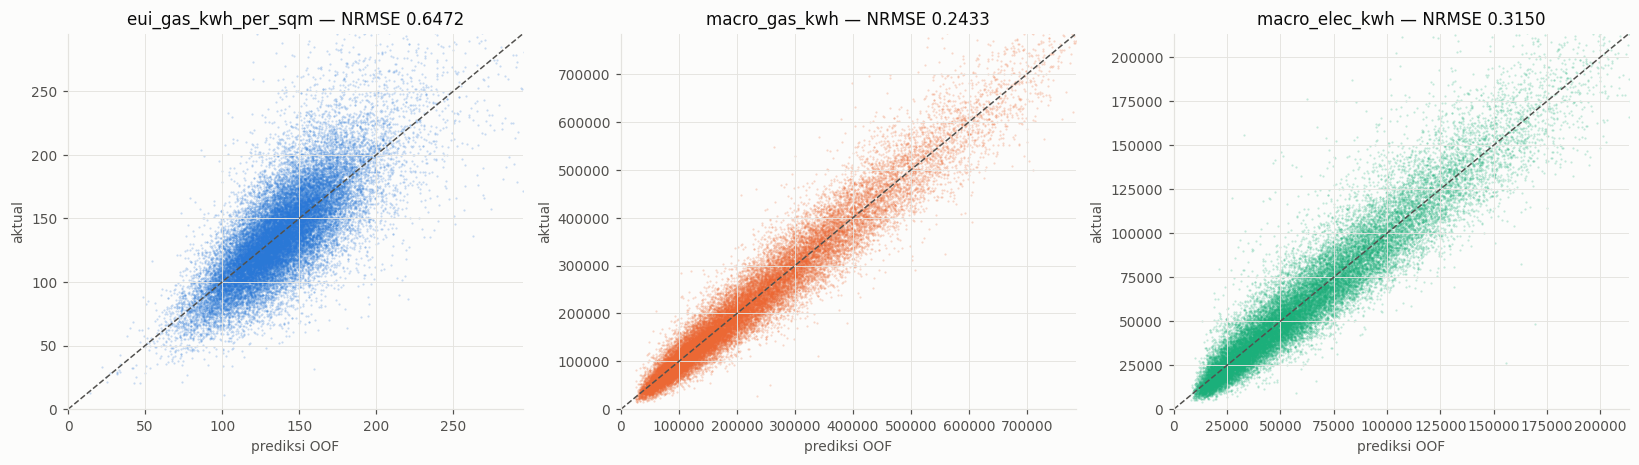

In [27]:
rows = []
for t in TARGETS:
    rows.append(dict(target=t, seen=nrmse(Y[t][so], oof_final[t][so], t), unseen=nrmse(Y[t][~so], oof_final[t][~so], t),
                     all=nrmse(Y[t], oof_final[t], t)))
seen_tab = pd.DataFrame(rows).set_index("target")
p_un_te = 1 - st.mean()
seen_tab["test_estimate"] = np.sqrt((1 - p_un_te) * seen_tab["seen"] ** 2 + p_un_te * seen_tab["unseen"] ** 2)
display(seen_tab.round(5))
print(f"Estimasi skor test (reweight seen/unseen sesuai proporsi test): {seen_tab['test_estimate'].mean():.5f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
for ax, t, col in zip(axes, [U, G, E], [C1, C2, C3]):
    idx = np.random.default_rng(SEED).choice(len(train), 30000, replace=False)
    ax.scatter(oof_final[t][idx], Y[t][idx], s=2, alpha=0.25, color=col, linewidths=0)
    lim = [0, np.quantile(Y[t], 0.995)]; ax.plot(lim, lim, color=INK2, linewidth=1, linestyle="--")
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_xlabel("prediksi OOF"); ax.set_ylabel("aktual")
    ax.set_title(f"{t.replace('target_', '')} — NRMSE {nrmse(Y[t], oof_final[t], t):.4f}")
plt.tight_layout(); plt.show()

### 11.2 Random KFold vs GroupKFold (zone)

In [28]:
RUN_SPATIAL_CHECK = True
if RUN_SPATIAL_CHECK:
    from sklearn.model_selection import GroupKFold
    Xq = train[FEATS].to_numpy(dtype=np.float32); yq = np.log(Y[U])
    Pq = dict(objective="regression", learning_rate=0.1, num_leaves=127, min_data_in_leaf=100, feature_fraction=0.5,
              bagging_fraction=0.8, bagging_freq=1, seed=SEED, deterministic=True, force_col_wise=True, verbose=-1, num_threads=N_THREADS)
    chk = {}
    for nm, splits in [("Random KFold (dipakai)", [(np.where(fold_id != k)[0], np.where(fold_id == k)[0]) for k in range(N_FOLDS)]),
                       ("GroupKFold zone_region_id", list(GroupKFold(N_FOLDS).split(Xq, groups=train["zone_region_id"])))]:
        p = np.zeros(len(yq))
        for itr, iva in splits:
            m = lgb.train(Pq, lgb.Dataset(Xq[itr], yq[itr]), R(400)); p[iva] = m.predict(Xq[iva], num_threads=N_THREADS)
        chk[nm] = nrmse(Y[U], np.exp(p), U)
    display(pd.Series(chk, name="NRMSE EUI (model cepat)").round(5).to_frame())
    del Xq; gc.collect()

,NRMSE EUI (model cepat)
Random KFold (dipakai),0.68962
GroupKFold zone_region_id,0.70811


## 12. Submisi

In [29]:
sub = pd.DataFrame({"id": test_raw["id"].values})
for t in TARGETS:
    sub[t] = test_final[t].astype(np.float64)

assert list(sub.columns) == list(sample_sub.columns), "header tidak sesuai"
assert len(sub) == len(sample_sub) == (20000 if FAST_DEV_RUN else 183987), "jumlah baris salah"
assert (sub["id"].values == sample_sub["id"].values).all(), "urutan id tidak sesuai sample_submission"
assert np.isfinite(sub[TARGETS].values).all(), "ada NaN/inf"
assert (sub[[G, E, U]] > 0).all().all(), "target energi harus positif"
assert sub[CL].between(0, 100).all() and sub[EH].between(0, 100).all(), "rasio harus 0-100"

SUB_PATH = OUT_DIR / ("submission_dev.csv" if FAST_DEV_RUN else "submission.csv")
sub.to_csv(SUB_PATH, index=False, float_format="%.6f")
md5 = hashlib.md5(open(SUB_PATH, "rb").read()).hexdigest()
print(f"Tersimpan: {SUB_PATH.resolve()} | shape {sub.shape} | MD5 {md5}")
display(sub.head())
display(pd.DataFrame({"test_pred_mean": sub[TARGETS].mean(), "train_target_mean": train[TARGETS].mean(),
                      "test_pred_std": sub[TARGETS].std(), "train_target_std": train[TARGETS].std()}).round(3))

Tersimpan: D:\ITS\S1\Lomba\FORTEX\penyisihan1\submission.csv | shape (183987, 6) | MD5 51fa8cef39f557852dec3190e0195f52


,id,target_macro_gas_kwh,target_macro_elec_kwh,target_eui_gas_kwh_per_sqm,target_clean_building_ratio,target_electric_heating_adoption
0,ID_429304,558420.825983,115811.698373,128.886226,86.84,14.285714
1,ID_429305,177545.045340,41884.662479,129.010596,100.00,8.235294
2,ID_429306,126749.431564,32919.955505,152.160074,92.31,7.500000
3,ID_429307,236176.574978,83922.616116,121.697652,81.82,2.068966
4,ID_429308,158071.763576,46015.163296,109.404192,100.00,0.000000


,test_pred_mean,train_target_mean,test_pred_std,train_target_std
target_macro_gas_kwh,230681.600,230372.428,147532.389,151750.038
target_macro_elec_kwh,63886.435,63755.899,39736.893,41725.369
target_eui_gas_kwh_per_sqm,138.918,139.063,30.705,40.652
target_clean_building_ratio,90.770,90.763,12.452,12.491
target_electric_heating_adoption,5.388,5.380,7.176,7.185
